# Ground truth on the probe stacks — analysis

The sanity tests and figures of `epanet_gt_V4`, on the pipeline's exact layer of the **probe stacks** the sensors are
chosen on and labelled from. Reads only `notebooks/outputs/epanet_gt_exact/` (written by `gt_compute.ipynb`); the dose
exponents come from `dose_response.ipynb` through it (absent → the dose panels are skipped).

| § | question |
|---|---|
| gates, L | are the exact numbers trustworthy (G-X…, G-D…)? how do the labels relate (size bias of N, Nr vs S, m_k vs S)? |
| A | which clients see which drifts — share of each client's links responding, median label; per topological class |
| S | do the labels depend on the floor? |
| P | what the numbers mean in the pipes: γ_S by group, the Nr–S plane, sensor cards, gallery, widget |
| X | how much of each response goes through the hub, and is that split unique? |
| M1–M4 | whose water passes each link — how mixed, how stable, does it predict dependence; bars per client |
| T, T2 | the placed sensors' labels over the periods and month by month; every link's monthly S, clustered |
| N | maps: partition and classes, exact channel per drift, the chain through the months |

**Differences from `epanet_gt_V4`.** Probe stacks (seed of the probes; world k converts district k), not the study's
worlds. Windows are the stack's: init = its baseline window, final = k's settled window, transition between — they
differ per drifting district k. Tables hold the placement candidates only (pumps, valves, dead and low-flow links out).
Card series exist for every link, not only the placed sensors, but only for two weeks (the first and last of k's
settled window). Dropped: C, RE, r²ₜ, systematic share, and the comparisons against the old estimator. The legacy
"storage class" of a link (`storage_class_eval_v2`) is replaced by the exact channel of each response (σ).

In [1]:
%matplotlib inline
import warnings, sys, pathlib, json
from pathlib import Path
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from matplotlib.colors import LogNorm
from matplotlib.collections import LineCollection
from matplotlib.lines import Line2D
from scipy.cluster.hierarchy import linkage, leaves_list, dendrogram
import ipywidgets as ipw
from IPython.display import display, Markdown

REPO = next((p for p in [pathlib.Path.cwd(), *pathlib.Path.cwd().parents]
             if (p / "src" / "fedwater").is_dir()), None)
assert REPO is not None, "run this from inside the fedwater repo"
warnings.filterwarnings("ignore")
pd.set_option("display.width", 230, "display.max_columns", 60, "display.max_rows", 300)
plt.rcParams.update({"figure.dpi": 90, "font.size": 9})

GT = REPO / "notebooks" / "outputs" / "epanet_gt_exact"          # gt_compute.ipynb's output: the only input here
MAN = json.loads((GT / "manifest.json").read_text())
FLOOR, GAMMA_MIN, M_FLOOR, TAX = MAN["floor"], MAN["gamma_min"], MAN["m_floor"], MAN["taxonomy"]
METRICS = MAN["metrics"]
CH_LO, CH_HI = float(TAX["ch_lo"]), float(TAX["ch_hi"])
TB = {f.stem: pd.read_parquet(f) for f in sorted(GT.glob("*.parquet"))}
for df in TB.values():
    if {"network", "partition"} <= set(df.columns):
        df["part"] = df["network"] + " / " + df["partition"]
    if "element" in df.columns:
        df["element"] = df["element"].astype(str)
LBL, LKS, MON, CMP, PER = TB["labels"], TB["links"], TB["monthly"], TB["composition"], TB["periods"]
LF = LBL[LBL["period"] == "final"].copy()
PARTS = list(dict.fromkeys(LF["part"]))
DOSE = LF["gamma_S"].notna().any()
PLACED = {p: set(LKS[(LKS["part"] == p) & LKS["placed"].astype(bool)]["element"]) for p in PARTS}
CAND = LKS[LKS["candidate"].astype(bool)]
DISTS = sorted(set(LF["k"]))
DCOL = {d: plt.get_cmap("tab10")(i) for i, d in enumerate(DISTS)}
TOPOS = [t for t in ("branch", "loop", "source_bridge") if t in set(LF["topo"])]
short = lambda d: str(d).replace("District_", "")


def win_of(p, k):
    r = PER[(PER["part"] == p) & (PER["k"] == k)].iloc[0]
    return {"init": (int(r.init_lo), int(r.init_hi)), "transition": (int(r.init_hi), int(r.final_lo)),
            "final": (int(r.final_lo), int(r.final_hi)), "sm": int(r.steps_month), "sd": int(r.steps_day)}


display(pd.DataFrame(MAN["targets"]))
print(f"{len(PARTS)} partition(s); dose exponents {'present' if DOSE else 'absent (run dose_response.ipynb)'}")

,network,partition,stack,exact,world (placement),gates,districts
0,dtown,fast_greedy,1c0918c6dc18,e8dcb0db4133,0ed323104afb,14/14,5
1,dtown,girvan_newman,f8d3ae7d6e79,76da6583e12e,6b4c52748c9b,14/14,5


2 partition(s); dose exponents present


## Gates and how the labels relate

| gate | check |
|---|---|
| G-X0 / X0b / X0c | runs complete and converged; one network model; drift worlds re-simulated = the stored probe worlds |
| G-X1, G-X2 | splice exact; probe flows = no-drift city before the drift |
| G-X3 | branch response = downstream demand change (gain units) |
| G-X4a/b, G-X5 | E1 rows sum to 1, parts sum to the flow; branch composition = downstream demand shares |
| G-X6a / X6d | twin(0, traj0) reproduces the no-drift city; twin(k, traj k) − twin(0, traj0) reproduces the drift's response (gain units) |
| G-X6b / X6e / X6c | every twin hour has a head reference (no-drift / drift trajectories); no storage share on branches |
| G-D0 / D1 / D2 | dose runs complete; identical before the drift; λ = 1 reproduces the probe world |

In [2]:
# gates of every stack (exact layer G-X..., dose runs G-D...) and how the labels relate (off-diagonal, final window)
G_ = TB["gates"]
display(G_.pivot_table(index=["source", "gate", "check"], columns="part", values="value", aggfunc="first"))
GATES_OK = bool(G_["passed"].all())
display(Markdown(f"**{'All gates pass.' if GATES_OK else 'A gate FAILED -- do not read the sections below before it is understood.'}**"))
display(Markdown("**How the labels relate** (off-diagonal cells, final window). N's correlation with the link's flow is "
                 "its size bias; Nr divides it out. γ_S: dose exponent of S on the responding cells."))
display(TB["relations"].set_index("part").drop(columns=["network", "partition"]).round(3))

part                                                               dtown / fast_greedy  dtown / girvan_newman
source gate  check                                                                                           
dose   G-D0  dose runs reached the horizon, converged                   0 / 15 failing         0 / 15 failing
       G-D1  dosed flows = no-drift city before the drift                      0.0e+00                0.0e+00
       G-D2  lambda 1 re-run = the stored probe world                          2.4e-07                2.4e-07
exact  G-X0  every run reached the horizon, converged                   0 / 22 failing         0 / 22 failing
       G-X0b one network model across the probe worlds                      1 distinct             1 distinct
       G-X0c drift worlds re-simulated through the toolkit l...                2.2e-07                2.2e-07
       G-X1  splice exact (non-drifting demand equal across ...                0.0e+00                0.0e+00
       G-X2  probe flows = no-drift city before the drift (m...                2.2e-07                2.2e-07
       G-X3  branch response = downstream demand change (gai...                1.9e-08                2.5e-08
       G-X4a E1 destination shares of every node sum to 1                      2.2e-15                2.4e-15
       G-X4b E1 destination parts of every link sum to its |...                2.0e-15                2.4e-15
       G-X5  E1 branch composition = downstream demand shares                  0.0e+00                0.0e+00
       G-X6a twin(0, traj0) reproduces the no-drift city (ga...  5.5e-07 (1.7e-03 L/s)  7.5e-07 (3.5e-03 L/s)
       G-X6b every twin hour has a head reference                                    0                      0
       G-X6c no storage share on branches (|g_ie0|)                            1.9e-08                2.5e-08
       G-X6d twin(k, traj k) - twin(0, traj0) reproduces the...  2.8e-07 (2.7e-03 L/s)  1.0e-06 (7.2e-03 L/s)
       G-X6e every hour of every drift trajectory has a head...                      0                      0

**All gates pass.**

**How the labels relate** (off-diagonal cells, final window). N's correlation with the link's flow is its size bias; Nr divides it out. γ_S: dose exponent of S on the responding cells.

,cells,"rho(Nr,S)","rho(N,S)","rho(N, link flow)","rho(Nr, link flow)",Nr >= 0.05,S >= 0.25,median gamma_S (S responds),"rho(m_k, S)","rho(|dm_k|, S)"
part,,,,,,,,,,
dtown / fast_greedy,1688,0.827,0.850,0.831,0.67,0.277,0.246,0.355,0.697,0.695
dtown / girvan_newman,1680,0.859,0.881,0.834,0.65,0.245,0.221,0.240,0.731,0.743


## A · Client-pair matrices

Share of client $j$'s candidate links (all, and placed sensors) whose label responds to $k$, per metric at its default
floor — including the shape label counted only where it grows with the drift ($\gamma_S\ge$ `GAMMA_MIN`); then the
median label (continuous, no floor), all links vs placed; then per topological class.

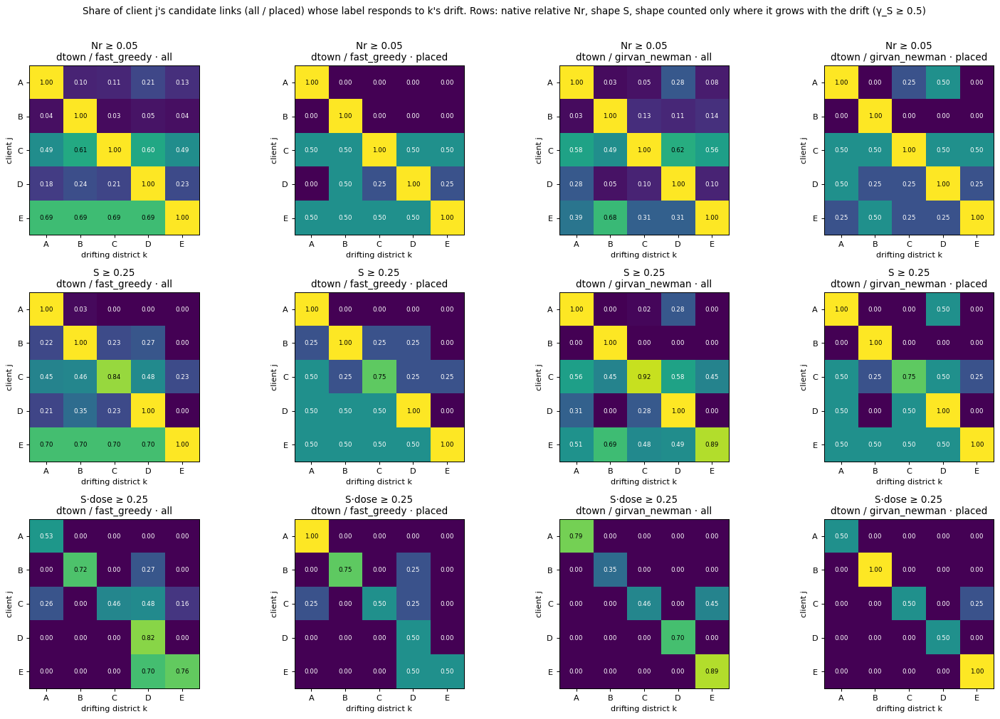

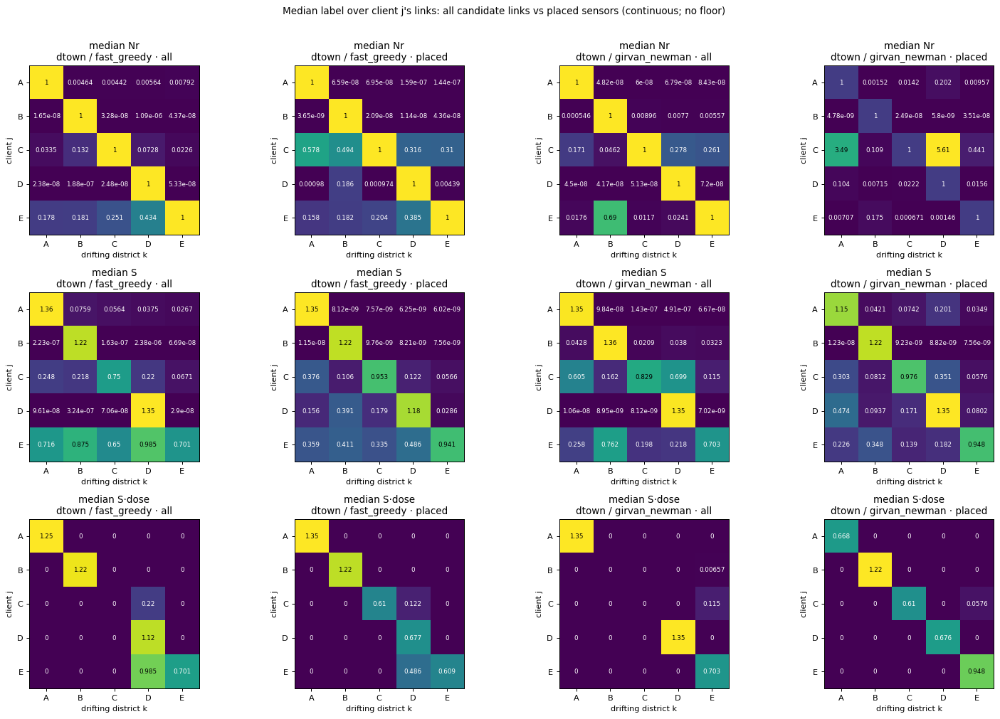

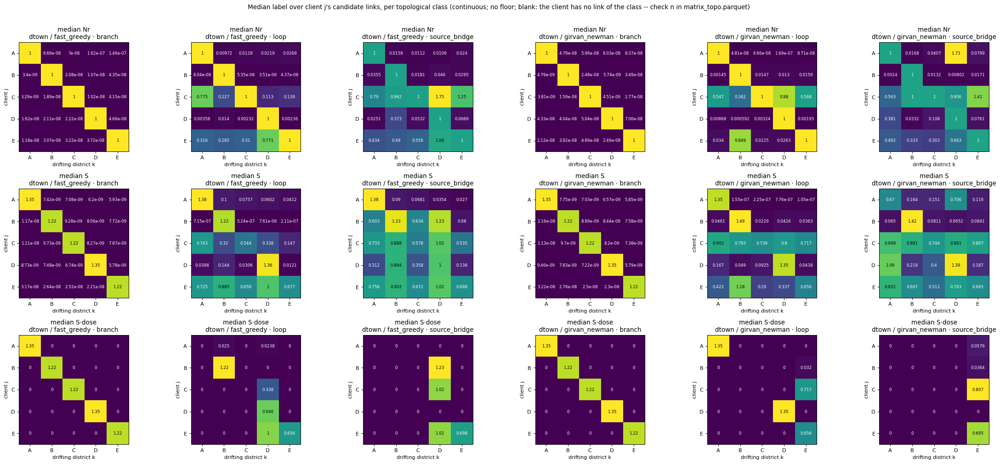

In [3]:
# A. client-pair matrices (final window): share of client j's candidate links whose label responds to k, and the median
MAT, MAT_T = TB["matrix"], TB["matrix_topo"]


def matrix_grid(df, value, title, scopes, vmax=1.0, fmt="{:.2f}"):
    cols = [(p, sc) for p in PARTS for sc in scopes]
    fig, axes = plt.subplots(len(METRICS), len(cols), figsize=(4.2 * len(cols), 3.8 * len(METRICS)), squeeze=False)
    for i, x in enumerate(METRICS):
        for j, (p, sc) in enumerate(cols):
            ax = axes[i, j]
            A = df[(df["part"] == p) & (df["scope"] == sc) & (df["metric"] == x)].pivot(index="j", columns="k", values=value)
            if not len(A) or not np.isfinite(A.to_numpy(float)).any():
                ax.axis("off"); continue
            V = A.to_numpy(float)
            top = vmax if vmax else max(np.nanmax(V), 1e-9)
            cm = plt.get_cmap("viridis").copy(); cm.set_bad("0.9")
            ax.imshow(np.ma.masked_invalid(V), vmin=0, vmax=top, cmap=cm)
            ax.set_xticks(range(A.shape[1]), [short(c) for c in A.columns])
            ax.set_yticks(range(A.shape[0]), [short(c) for c in A.index])
            for (a_, b_), v in np.ndenumerate(V):
                if np.isfinite(v):
                    ax.text(b_, a_, fmt.format(v), ha="center", va="center", fontsize=7, color="w" if v < 0.6 * top else "k")
            ax.set(xlabel="drifting district k", ylabel="client j",
                   title=(f"{x} ≥ {FLOOR[x]:g}" if value == "share" else f"median {x}") + f"\n{p} · {sc}")
    fig.suptitle(title); fig.tight_layout(rect=(0, 0, 1, 0.97)); plt.show()


matrix_grid(MAT, "share", "Share of client j's candidate links (all / placed) whose label responds to k's drift. Rows: "
            "native relative Nr, shape S" + (f", shape counted only where it grows with the drift (γ_S ≥ {GAMMA_MIN})"
                                             if "S·dose" in METRICS else ""), scopes=("all", "placed"))
matrix_grid(MAT, "median", "Median label over client j's links: all candidate links vs placed sensors (continuous; no floor)",
            scopes=("all", "placed"), vmax=None, fmt="{:.3g}")
matrix_grid(MAT_T, "median", "Median label over client j's candidate links, per topological class (continuous; no floor; "
            "blank: the client has no link of the class -- check n in matrix_topo.parquet)", scopes=tuple(TOPOS),
            vmax=None, fmt="{:.3g}")

## S · Sensitivity to the relevance floor

Each metric swept over its floor: cells responding (own / other / placed / loops), the district-blind share (links that
respond to every foreign drift), and branches that carry none of $k$'s water yet respond (physics: must be 0).

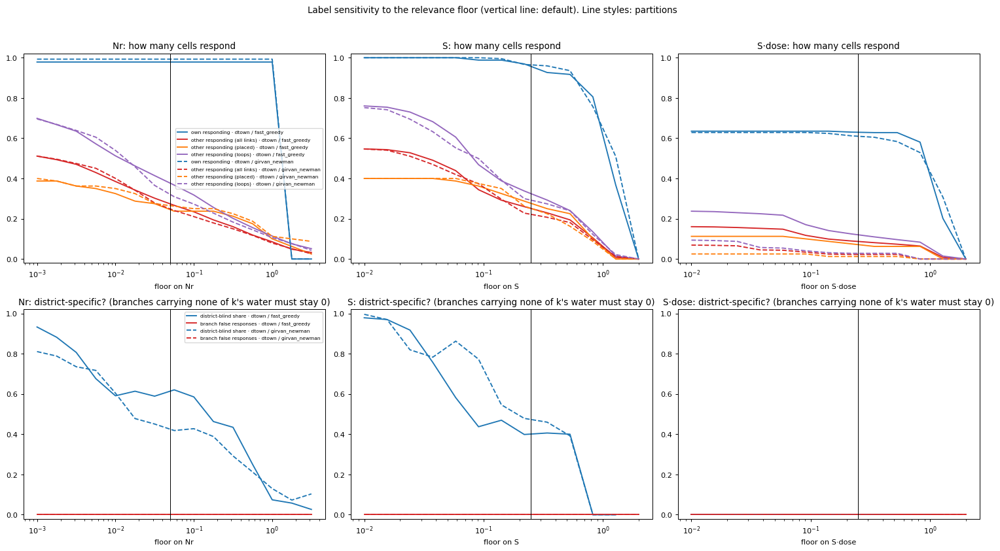

Read: a floor is defensible where the off-diagonal share is on a plateau, the district-blind share is low and branches never respond. At the default floor:

,metric,eps,own responding,other responding (all links),other responding (placed),other responding (loops),district-blind share,branch false responses,part
0,Nr,0.056,0.979,0.267,0.238,0.367,0.620,0.0,dtown / fast_greedy
1,Nr,0.056,0.993,0.241,0.262,0.309,0.418,0.0,dtown / girvan_newman
2,S,0.220,0.969,0.260,0.288,0.338,0.399,0.0,dtown / fast_greedy
3,S,0.220,0.967,0.228,0.262,0.300,0.479,0.0,dtown / girvan_newman
4,S·dose,0.220,0.630,0.089,0.075,0.124,0.000,0.0,dtown / fast_greedy
5,S·dose,0.220,0.612,0.023,0.012,0.028,0.000,0.0,dtown / girvan_newman


In [4]:
# S. sensitivity of the labels to the relevance floor
SENS = TB["sensitivity"]
panels = [("own responding", "other responding (all links)", "other responding (placed)", "other responding (loops)"),
          ("district-blind share", "branch false responses")]
ptitle = ["how many cells respond", "district-specific? (branches carrying none of k's water must stay 0)"]
fig, axes = plt.subplots(len(panels), len(METRICS), figsize=(5.6 * len(METRICS), 9.5), squeeze=False)
for j, x in enumerate(METRICS):
    for i, cols in enumerate(panels):
        ax = axes[i, j]
        for (p, q_), ls in zip(SENS[SENS["metric"] == x].groupby("part"), ("-", "--", ":", "-.")):
            for c, cc in zip(cols, ("#1f77b4", "#d62728", "#ff7f0e", "#9467bd")):
                if c in q_ and q_[c].notna().any():
                    ax.plot(q_["eps"], q_[c], ls=ls, color=cc, label=f"{c} · {p}")
        ax.axvline(FLOOR[x], color="k", lw=0.8)
        ax.set(xscale="log", ylim=(-0.02, 1.02), xlabel=f"floor on {x}", title=f"{x}: {ptitle[i]}")
        if j == 0:
            ax.legend(fontsize=6)
fig.suptitle("Label sensitivity to the relevance floor (vertical line: default). Line styles: partitions")
fig.tight_layout(rect=(0, 0, 1, 0.96)); plt.show()
display(Markdown("Read: a floor is defensible where the off-diagonal share is on a plateau, the district-blind share is "
                 "low and branches never respond. At the default floor:"))
display(SENS.groupby(["metric", "part"]).apply(
    lambda q: q.iloc[(q["eps"] - FLOOR[q.name[0]]).abs().argsort()[:1]]).reset_index(drop=True)
    .drop(columns=["network", "partition"]).round(3))

## P · Sanity: what the numbers mean in the pipes

Population: the dose exponent of S by group, and every off-diagonal cell in the Nr–S plane coloured by $\gamma_S$.
**Sensor cards** (any candidate link × drifting district; the first or last week of k's settled window): the flows with
and without the drift; ΔQ with the demand channel alone (hub held on the no-drift course, dashed) and on k's own course
(dotted) — the two differ where the split is not unique; the same drift at reduced strength scaled back by 1/λ (curves
that coincide = proportional); pumps switched differently; ΔQ against ΔD_k hour by hour; the native and the z-scored
weekly profiles (what a client sees); where the link's water goes hour by hour with and without the drift (E1); the
label month by month. The gallery picks links by their numbers; the widget opens any candidate link.

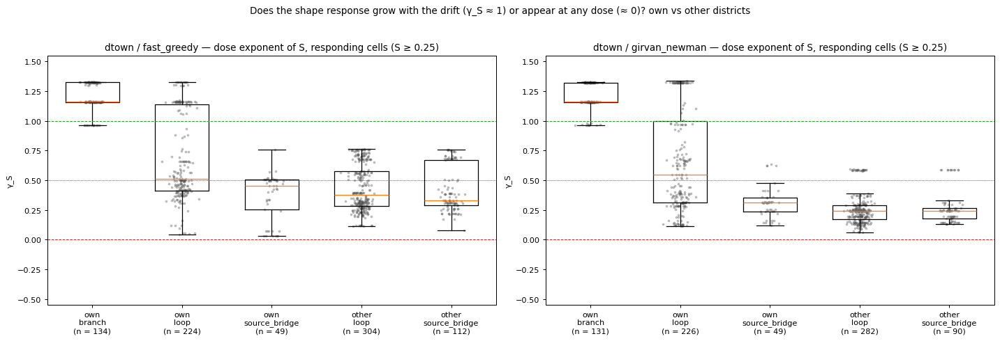

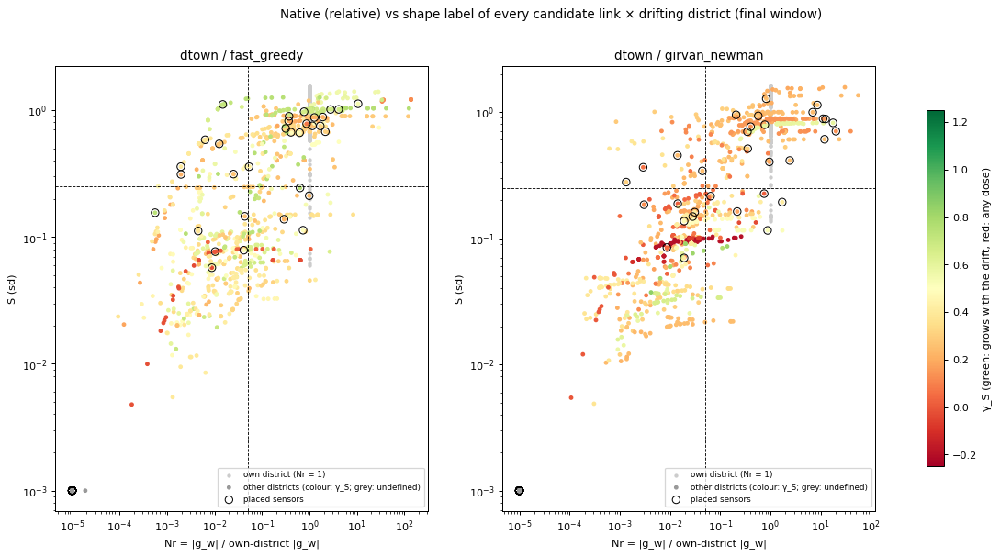

In [5]:
# P. sanity: how the numbers relate to what happens in the pipes (probe stack, final window)
TF = LF.copy()
TF["group"] = np.where(TF["own"], "own · ", "other · ") + TF["topo"]
order = [g for g in ("own · branch", "own · loop", "own · source_bridge", "other · loop", "other · source_bridge")
         if g in set(TF["group"])]
rng = np.random.default_rng(0)
if DOSE:
    fig, axes = plt.subplots(1, len(PARTS), figsize=(8 * len(PARTS), 5.5), squeeze=False)
    for j, p in enumerate(PARTS):
        ax = axes[0, j]
        q_ = TF[(TF["part"] == p) & (TF["S"] >= FLOOR["S"])]
        data = [q_[q_["group"] == g_]["gamma_S"].dropna().clip(-0.5, 1.5) for g_ in order]
        ax.boxplot(data, widths=0.6, showfliers=False)
        for x_, d_ in enumerate(data, start=1):
            ax.scatter(rng.normal(x_, 0.06, len(d_)), d_, s=4, alpha=0.3, color="#555")
        ax.axhline(1, color="#2ca02c", lw=0.8, ls="--"); ax.axhline(0, color="#d62728", lw=0.8, ls="--")
        ax.axhline(GAMMA_MIN, color="k", lw=0.6, ls=":")
        ax.set_xticks(range(1, len(order) + 1), [f"{o.replace(' · ', chr(10))}\n(n = {len(d)})" for o, d in zip(order, data)])
        ax.set(ylim=(-0.55, 1.55), ylabel="γ_S", title=f"{p} — dose exponent of S, responding cells (S ≥ {FLOOR['S']})")
    fig.suptitle("Does the shape response grow with the drift (γ_S ≈ 1) or appear at any dose (≈ 0)? own vs other districts")
    fig.tight_layout(rect=(0, 0, 1, 0.95)); plt.show()

fig, axes = plt.subplots(1, len(PARTS), figsize=(8 * len(PARTS), 7), squeeze=False)
for j, p in enumerate(PARTS):
    ax = axes[0, j]
    q_ = TF[TF["part"] == p]
    o_, x_ = q_[q_["own"]], q_[~q_["own"]]
    ax.scatter(o_["Nr"].clip(1e-5), o_["S"].clip(1e-3), s=6, color="0.8", label="own district (Nr = 1)")
    if DOSE:
        sc = ax.scatter(x_["Nr"].clip(1e-5), x_["S"].clip(1e-3), s=8, c=x_["gamma_S"].clip(-0.25, 1.25), cmap="RdYlGn",
                        vmin=-0.25, vmax=1.25, label="other districts (colour: γ_S; grey: undefined)", plotnonfinite=True)
        sc.cmap.set_bad("0.6")
    else:
        ax.scatter(x_["Nr"].clip(1e-5), x_["S"].clip(1e-3), s=8, color="#d62728", label="other districts")
    pl = x_[x_["placed"].astype(bool)]
    ax.scatter(pl["Nr"].clip(1e-5), pl["S"].clip(1e-3), s=44, facecolors="none", edgecolors="k", lw=0.8, label="placed sensors")
    ax.axvline(FLOOR["Nr"], color="k", lw=0.7, ls="--"); ax.axhline(FLOOR["S"], color="k", lw=0.7, ls="--")
    ax.set(xscale="log", yscale="log", xlabel="Nr = |g_w| / own-district |g_w|", ylabel="S (sd)", title=p)
    ax.legend(fontsize=7, loc="lower right")
if DOSE:
    fig.colorbar(sc, ax=axes.ravel().tolist(), shrink=0.8, label="γ_S (green: grows with the drift, red: any dose)")
fig.suptitle("Native (relative) vs shape label of every candidate link × drifting district (final window)")
plt.show()

#### dtown / fast_greedy · own district, branch: exact and proportional

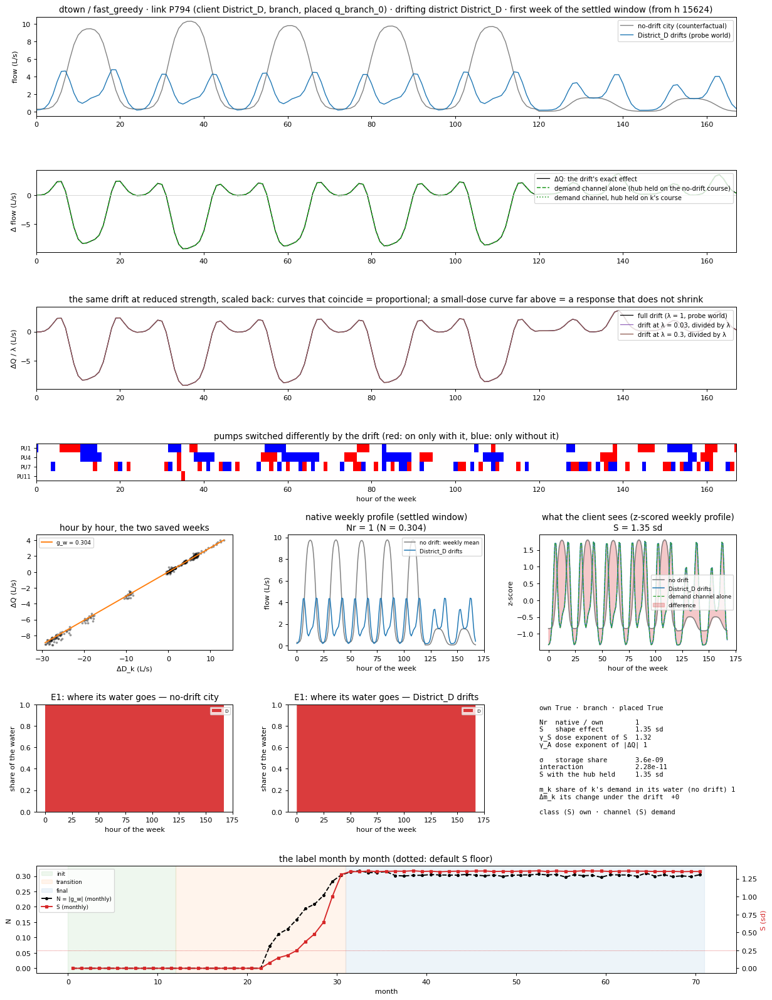

#### dtown / fast_greedy · own district, loop / source bridge

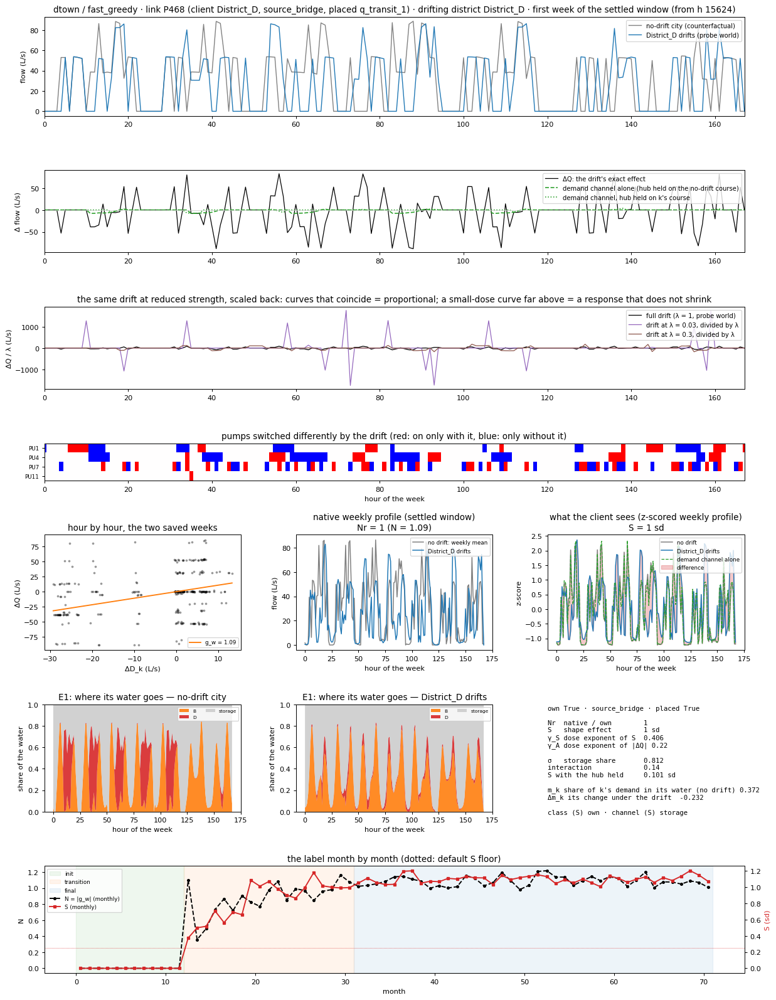

#### dtown / fast_greedy · other district: strongest shape response

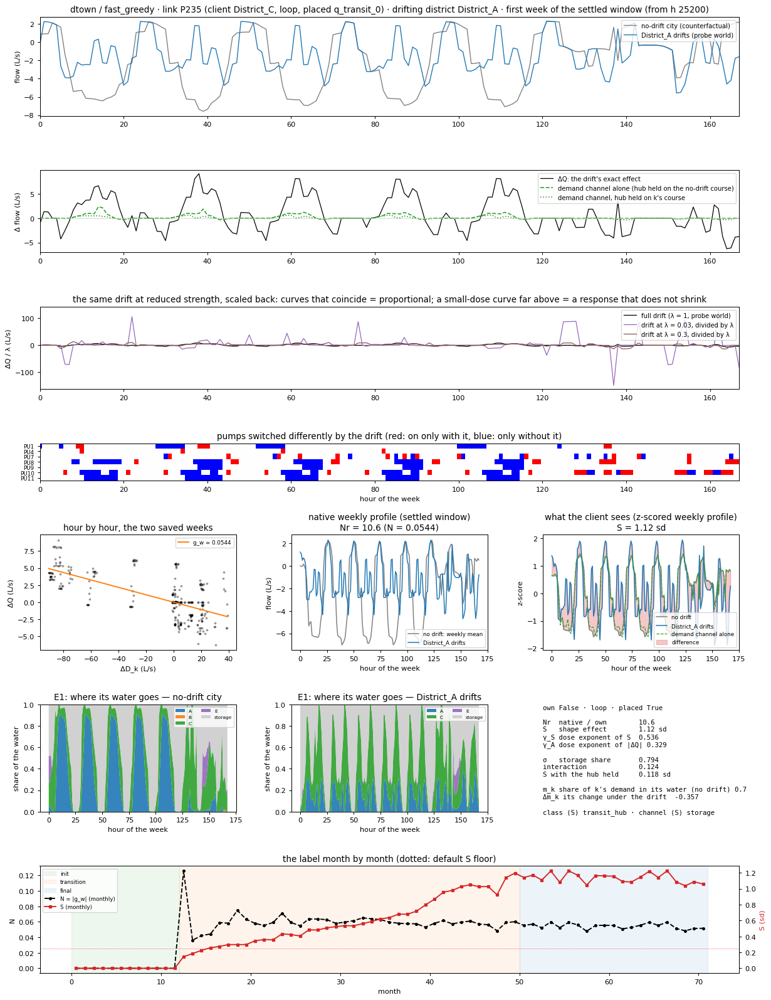

#### dtown / fast_greedy · other district: responds, least dose-driven (smallest γ_S)

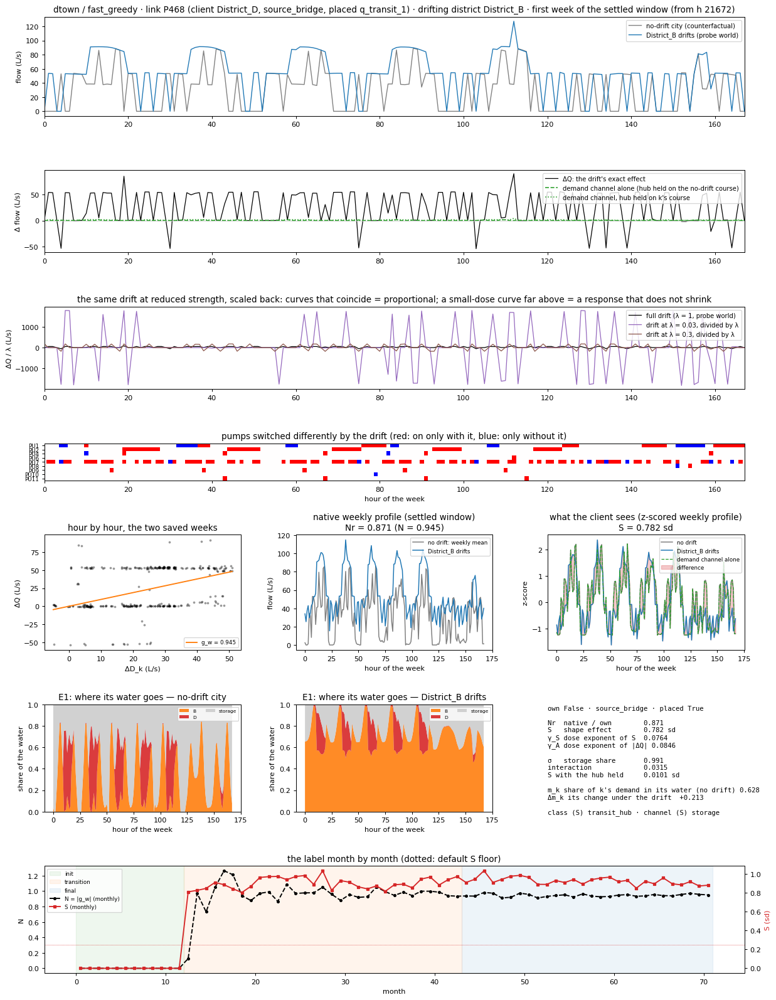

#### dtown / fast_greedy · other district: responds, most dose-driven (largest γ_S)

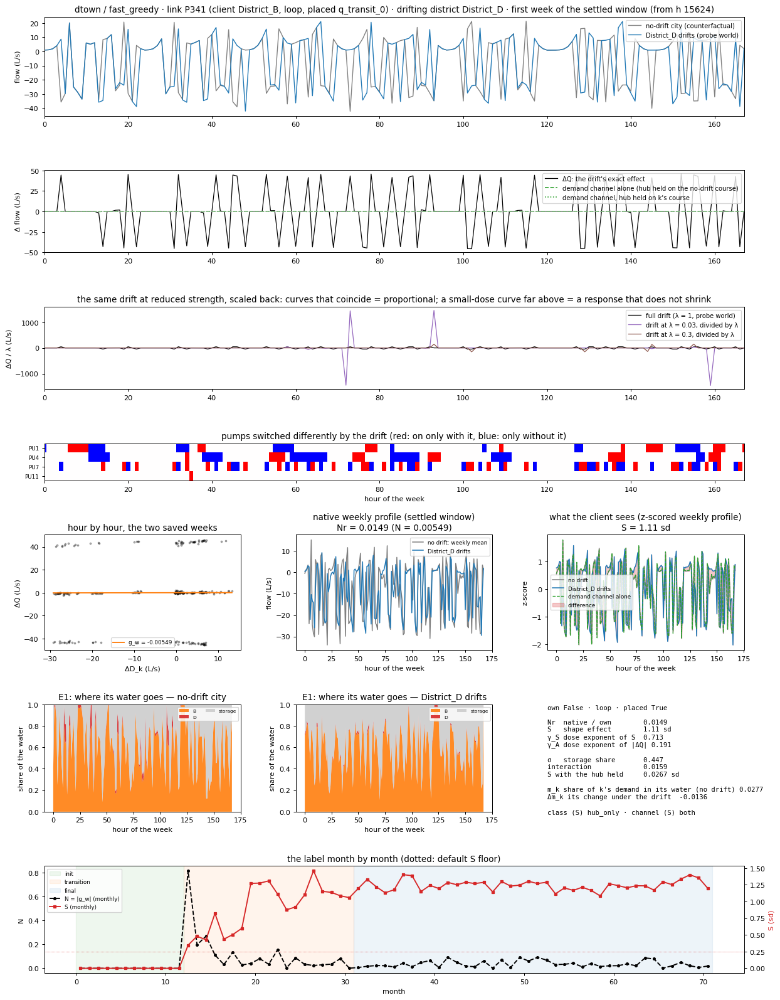

#### dtown / fast_greedy · other district: largest interaction (split not unique)

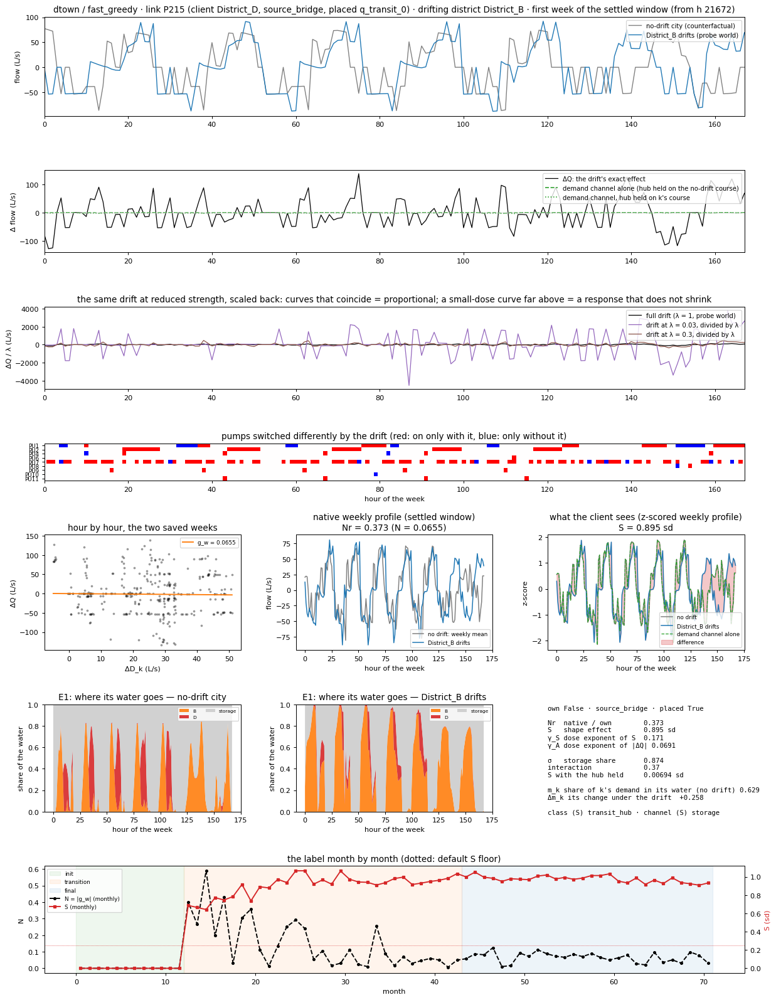

#### dtown / fast_greedy · other district: native only

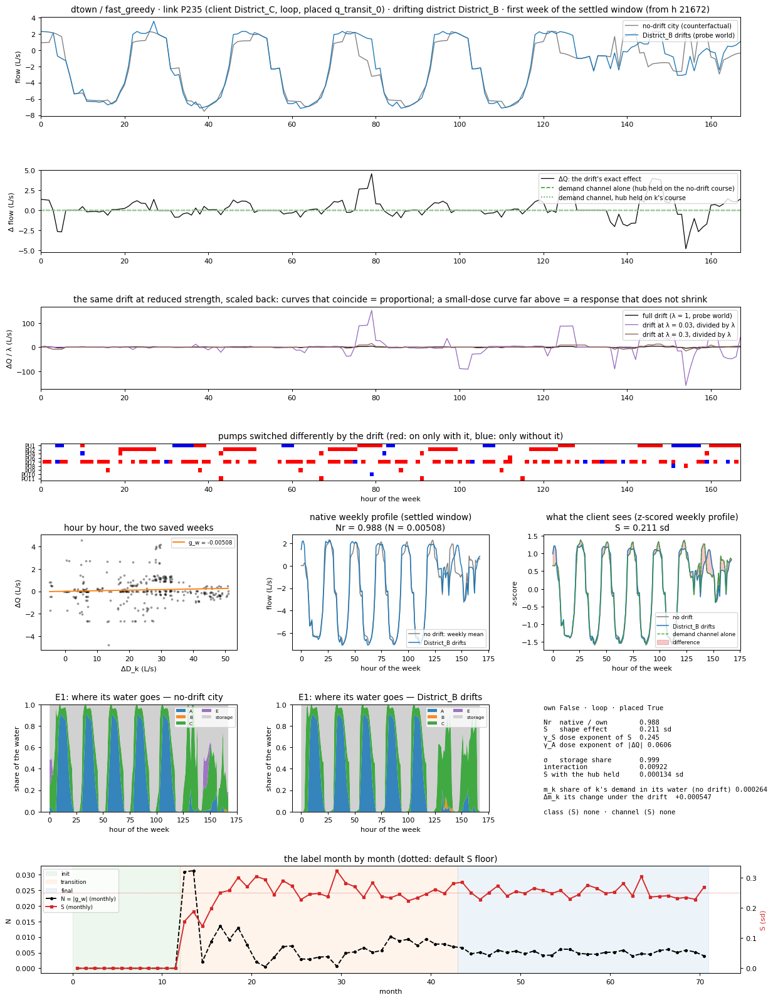

#### dtown / fast_greedy · other district: shape only

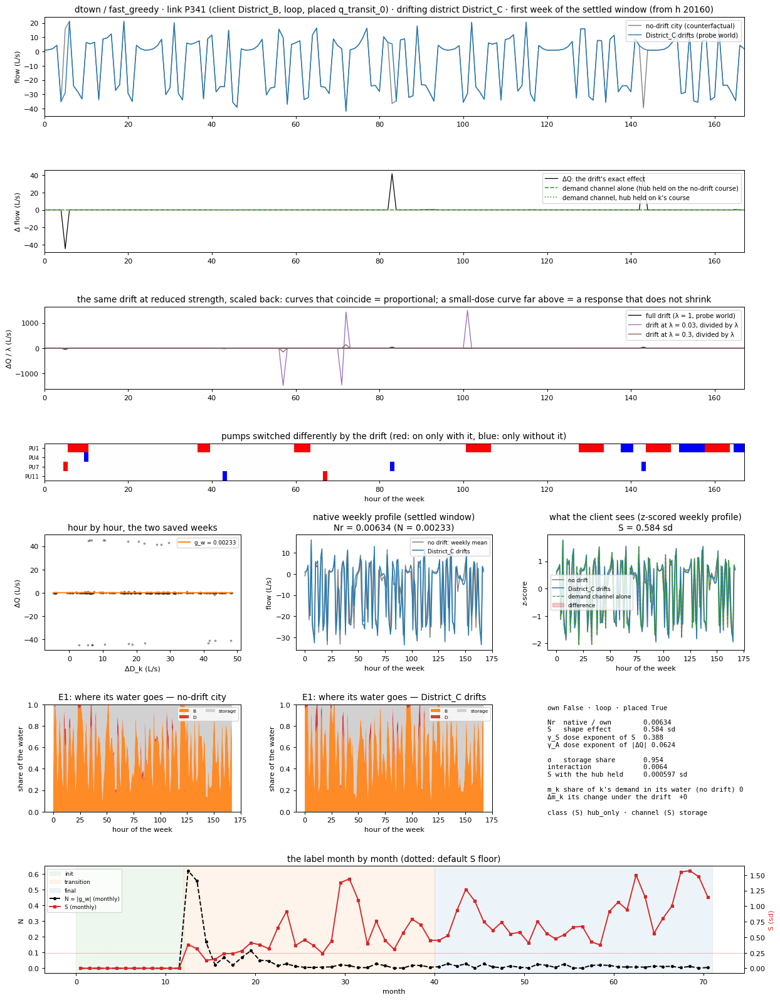

#### dtown / girvan_newman · own district, branch: exact and proportional

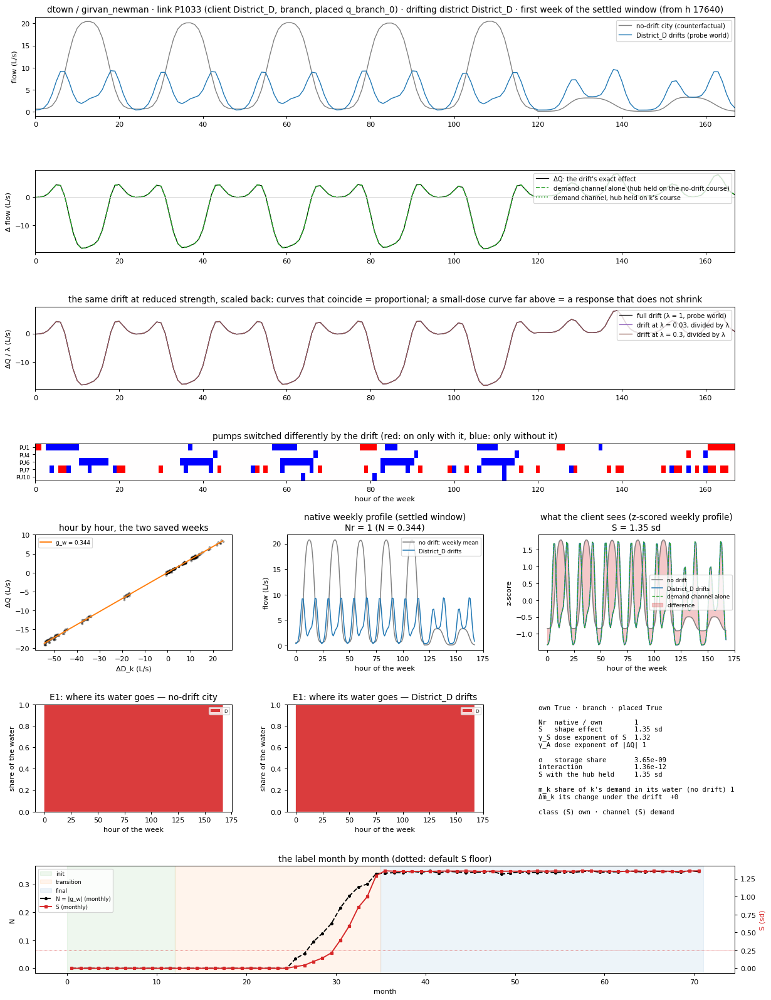

#### dtown / girvan_newman · own district, loop / source bridge

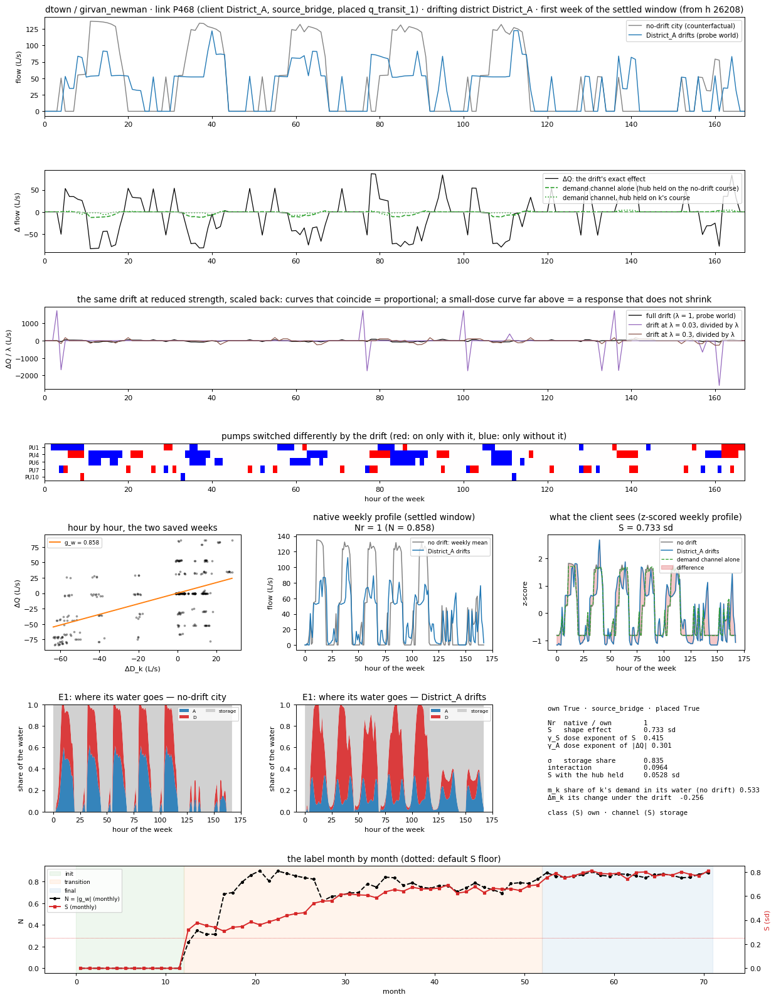

#### dtown / girvan_newman · other district: strongest shape response

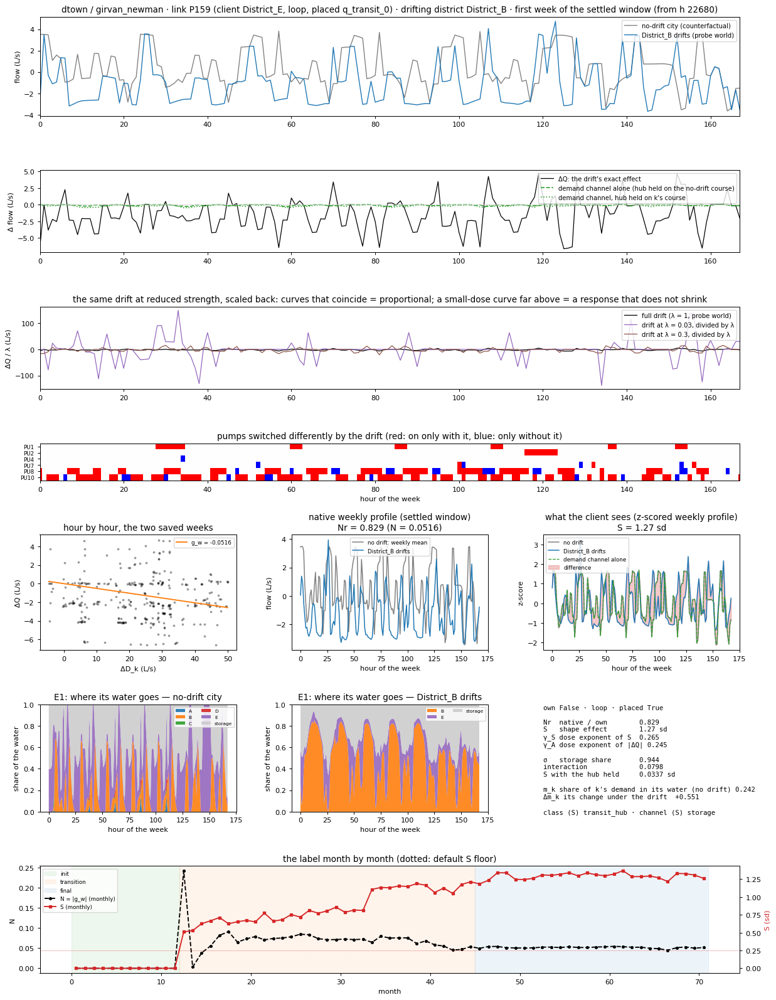

#### dtown / girvan_newman · other district: responds, least dose-driven (smallest γ_S)

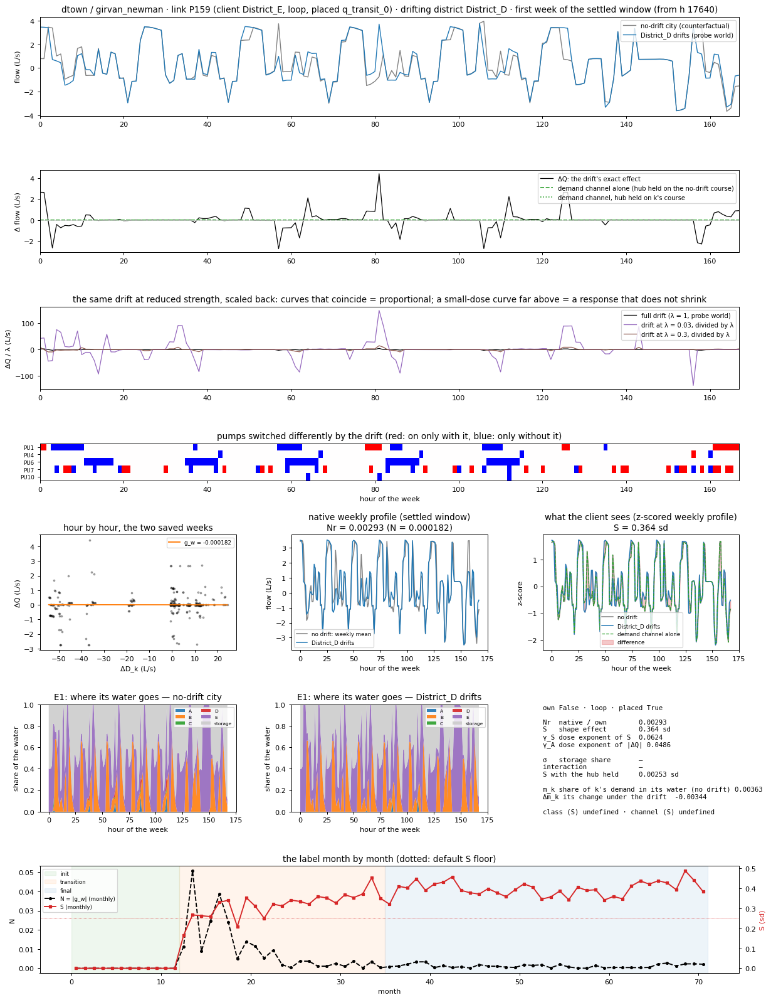

#### dtown / girvan_newman · other district: responds, most dose-driven (largest γ_S)

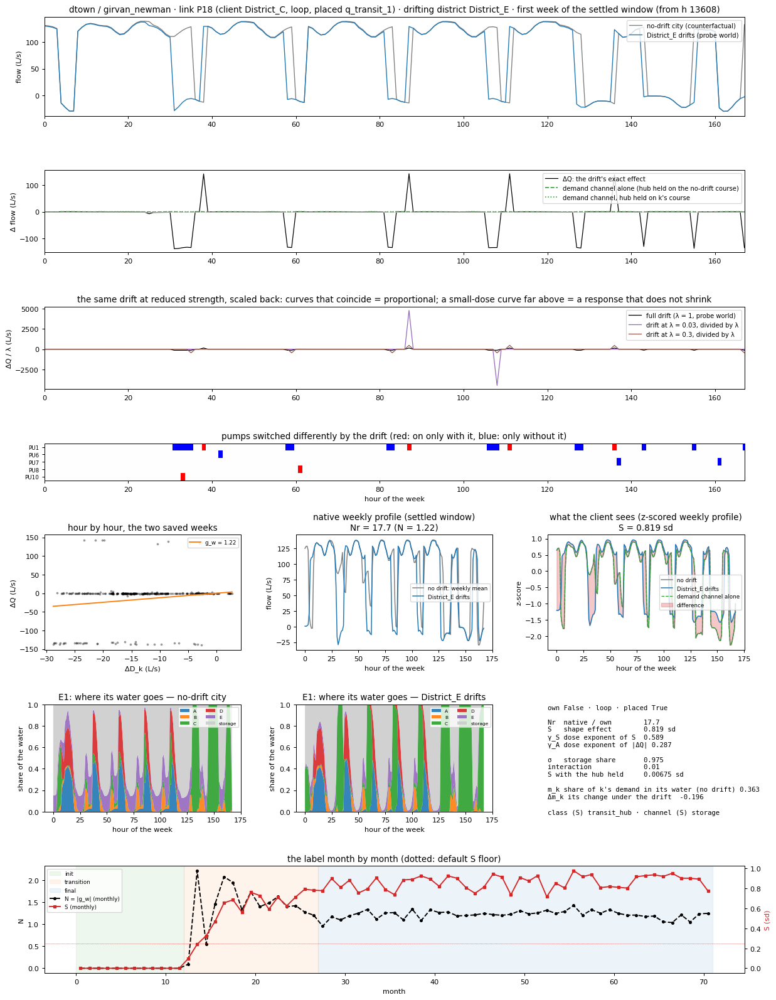

#### dtown / girvan_newman · other district: largest interaction (split not unique)

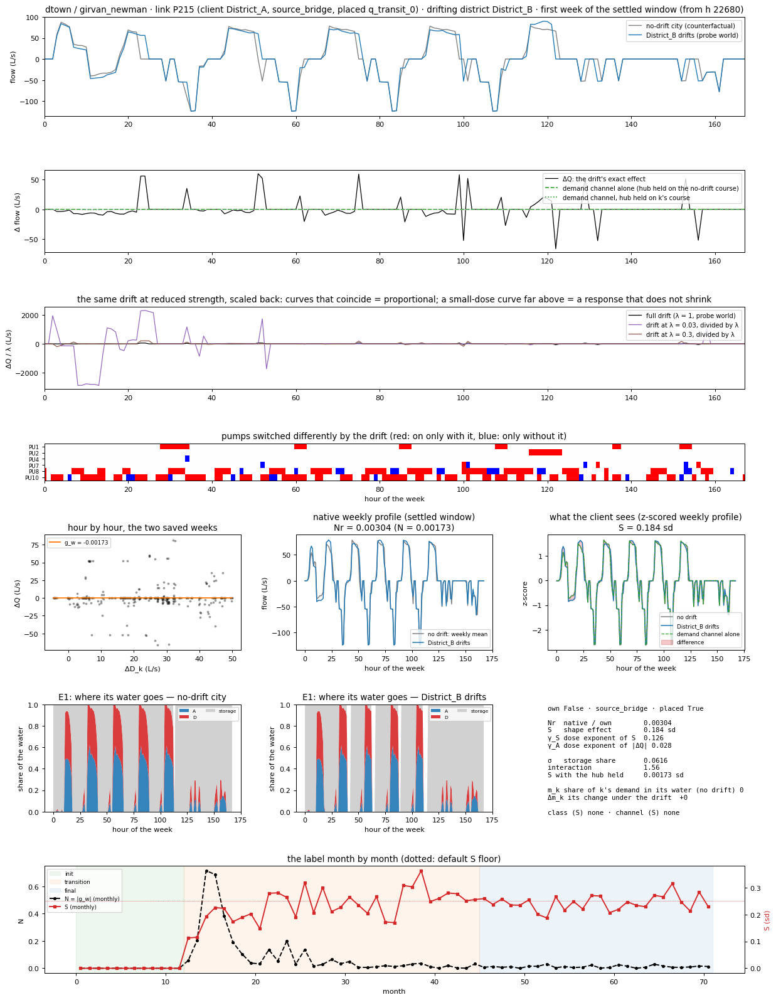

#### dtown / girvan_newman · other district: native only

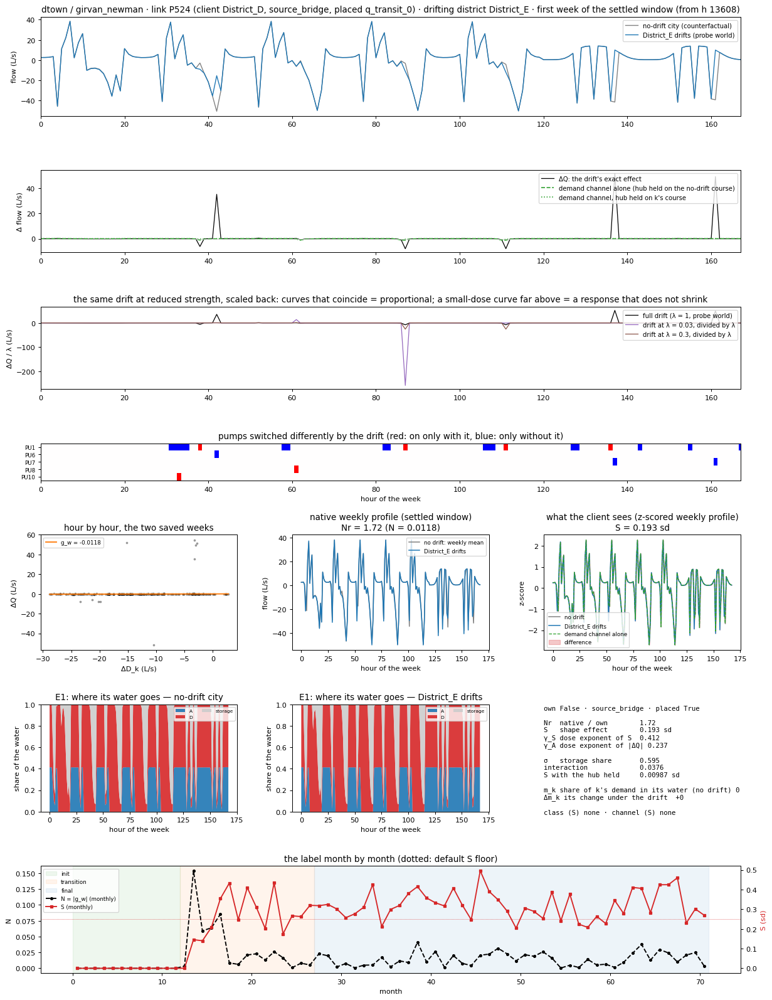

#### dtown / girvan_newman · other district: shape only

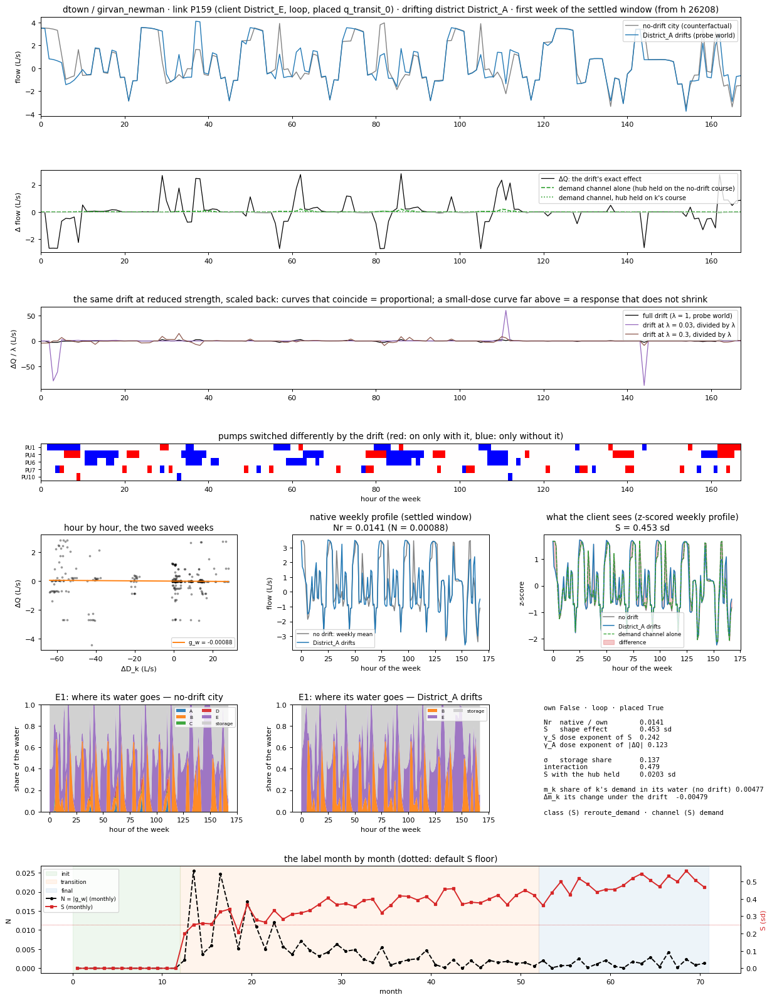

In [6]:
# ---- sensor cards: one link x one drifting district (probe stack, k's settled window, its first / last week) --------
CARDS = TB["cards"]
_CARD = {}


def card_of(p, k, kind="exact", lam=None):
    q_ = CARDS[(CARDS["part"] == p) & (CARDS["k"] == k) & (CARDS["kind"] == kind)]
    if lam is not None:
        q_ = q_[np.isclose(q_["lam"], lam)]
    if not len(q_):
        return None
    f = GT / q_["file"].iloc[0]
    if f not in _CARD:
        with np.load(f, allow_pickle=False) as z:
            _CARD[f] = {n: z[n] for n in z.files}
    return _CARD[f]


def sensor_card(p, k, element, week=0):
    c = card_of(p, k)
    if c is None:
        print("no card series for", p, k); return
    links = [str(x) for x in c["links"]]
    if element not in links:
        print(f"{element}: not in the card series"); return
    i = links.index(element)
    names = [str(d) for d in c["districts"]]
    jk = names.index(k)
    sd = int(c["steps_day"]); P_ = 7 * sd
    w = int(np.clip(week, 0, 1))
    wk_lo = int(c["weeks"][w])
    t = np.arange(P_)
    Wn = lambda run: c[f"week__{run}"][w][:, i].astype(float) if f"week__{run}" in c else None
    q0, q1 = Wn("nodrift"), Wn("drift")
    row = LF[(LF["part"] == p) & (LF["k"] == k) & (LF["element"] == element)]
    row = row.iloc[0] if len(row) else None
    lk = LKS[(LKS["part"] == p) & (LKS["element"] == element)].iloc[0]
    W = win_of(p, k)
    fig = plt.figure(figsize=(16, 22))
    gs = fig.add_gridspec(7, 3, height_ratios=[1.2, 1.0, 1.0, 0.45, 1.4, 1.3, 1.3], hspace=0.6, wspace=0.28)
    ax0 = fig.add_subplot(gs[0, :])
    ax0.plot(t, q0, color="0.5", lw=1.1, label="no-drift city (counterfactual)")
    ax0.plot(t, q1, color="#1f77b4", lw=1.1, label=f"{k} drifts (probe world)")
    ax0.set(ylabel="flow (L/s)", xlim=(0, P_ - 1),
            title=f"{p} · link {element} (client {lk['home']}, {lk['topo']}{', placed ' + str(lk['slot']) if lk['placed'] else ''})"
                  f" · drifting district {k} · {'first' if w == 0 else 'last'} week of the settled window (from h {wk_lo})")
    ax0.legend(fontsize=8, loc="upper right")
    ax = fig.add_subplot(gs[1, :], sharex=ax0)
    ax.plot(t, q1 - q0, color="k", lw=1.0, label="ΔQ: the drift's exact effect")
    for (a_, b_), ls, lab_ in ((("twin_k_traj0", "twin_0_traj0"), "--", "demand channel alone (hub held on the no-drift course)"),
                               (("twin_k_trajk", "twin_0_trajk"), ":", "demand channel, hub held on k's course")):
        A_, B_ = Wn(a_), Wn(b_)
        if A_ is not None and B_ is not None:
            ax.plot(t, A_ - B_, color="#2ca02c", lw=1.3, ls=ls, label=lab_)
    ax.axhline(0, color="0.8", lw=0.6); ax.set(ylabel="Δ flow (L/s)"); ax.legend(fontsize=8, loc="upper right")
    ax = fig.add_subplot(gs[2, :], sharex=ax0)
    dose_rows = CARDS[(CARDS["part"] == p) & (CARDS["k"] == k) & (CARDS["kind"] == "dose")]
    if len(dose_rows):
        ax.plot(t, q1 - q0, color="k", lw=1.0, label="full drift (λ = 1, probe world)")
        for lam, cc in zip(sorted(l for l in dose_rows["lam"] if l < 1), ("#9467bd", "#8c564b", "#e377c2")):
            dc = card_of(p, k, "dose", lam)
            dl = [str(x) for x in dc["links"]]
            if element in dl and int(dc["weeks"][w]) == wk_lo:
                ax.plot(t, (dc["week"][w][:, dl.index(element)].astype(float) - q0) / lam, color=cc, lw=1.0,
                        label=f"drift at λ = {lam:g}, divided by λ")
        ax.set(ylabel="ΔQ / λ (L/s)", title="the same drift at reduced strength, scaled back: curves that coincide = "
                                              "proportional; a small-dose curve far above = a response that does not shrink")
        ax.legend(fontsize=8, loc="upper right")
    else:
        ax.axis("off"); ax.set_title("no dose runs (dose_response.ipynb) on this exact layer")
    ax = fig.add_subplot(gs[3, :], sharex=ax0)
    pumps = LKS[(LKS["part"] == p) & LKS["is_pump"].astype(bool)]["element"].tolist()
    pix = [links.index(x) for x in pumps if x in links]
    if pix:
        on = lambda run: np.abs(c[f"week__{run}"][w][:, pix].astype(float)) > 1e-6 * np.maximum(
            np.abs(c[f"week__{run}"][:, :, pix].astype(float)).max(axis=(0, 1)), 1e-12)
        dU = (on("drift").astype(int) - on("nodrift").astype(int)).T
        busy = np.abs(dU).sum(axis=1) > 0
        if busy.any():
            ax.imshow(dU[busy], aspect="auto", cmap="bwr", vmin=-1, vmax=1, interpolation="nearest",
                      extent=(-0.5, P_ - 0.5, busy.sum() - 0.5, -0.5))
            ax.set_yticks(range(busy.sum()), [x for x, b in zip([links[q] for q in pix], busy) if b], fontsize=7)
    ax.set(xlabel="hour of the week", title="pumps switched differently by the drift (red: on only with it, blue: only without it)")

    ax = fig.add_subplot(gs[4, 0])
    dQ2 = np.concatenate([c["week__drift"][v][:, i] - c["week__nodrift"][v][:, i] for v in (0, 1)]).astype(float)
    dD2 = np.concatenate([c["week__demand_drift"][v][:, jk] - c["week__demand_nodrift"][v][:, jk] for v in (0, 1)]).astype(float)
    ax.scatter(dD2, dQ2, s=4, alpha=0.3, color="k", rasterized=True)
    if row is not None and np.isfinite(row["g_w"]):
        xx = np.linspace(dD2.min(), dD2.max(), 10)
        ax.plot(xx, row["g_w"] * xx * np.sign(np.nanmean(q0) or 1.0), color="#ff7f0e", lw=1.5, label=f"g_w = {row['g_w']:.3g}")
        ax.legend(fontsize=7)
    ax.set(xlabel="ΔD_k (L/s)", ylabel="ΔQ (L/s)", title="hour by hour, the two saved weeks")
    ax = fig.add_subplot(gs[4, 1])
    P0, P1 = c["prof__nodrift"][i].astype(float), c["prof__drift"][i].astype(float)
    ax.plot(t, P0, color="0.5", lw=1.2, label="no drift: weekly mean"); ax.plot(t, P1, color="#1f77b4", lw=1.2, label=f"{k} drifts")
    ax.set(xlabel="hour of the week", ylabel="flow (L/s)",
           title=f"native weekly profile (settled window)\nNr = {row['Nr']:.3g} (N = {row['N']:.3g})" if row is not None else "")
    ax.legend(fontsize=7)
    ax = fig.add_subplot(gs[4, 2])
    z = lambda v: (v - v.mean()) / v.std() if v.std() > 1e-12 else v * np.nan
    ax.plot(t, z(P0), color="0.5", lw=1.2, label="no drift"); ax.plot(t, z(P1), color="#1f77b4", lw=1.2, label=f"{k} drifts")
    if "prof__twin_k_traj0" in c:
        Pd = c["prof__twin_k_traj0"][i].astype(float) - c["prof__twin_0_traj0"][i].astype(float) + P0
        ax.plot(t, z(Pd), color="#2ca02c", lw=1.0, ls="--", label="demand channel alone")
    ax.fill_between(t, z(P0), z(P1), color="#d62728", alpha=0.25, label="difference")
    ax.set(xlabel="hour of the week", ylabel="z-score",
           title=f"what the client sees (z-scored weekly profile)\nS = {row['S']:.3g} sd" if row is not None else "")
    ax.legend(fontsize=7)
    dests = [str(d) for d in c["dests"]]
    for col_, tag in enumerate(("nodrift", "drift")):
        ax = fig.add_subplot(gs[5, col_])
        H_ = c[f"how__{tag}"][i].astype(float)                              # 7sd x G (hour-of-week totals)
        tot = H_.sum(axis=1, keepdims=True)
        sh = np.nan_to_num(H_ / np.where(tot > 0, tot, np.nan))
        keepd = [q for q in range(len(dests)) if sh[:, q].max() > 0.01]
        cols_ = [DCOL.get(dests[q], "0.6") if dests[q] in DCOL else {"storage": "0.8", "reservoir": "0.3",
                                                                      "unaccounted": "k"}[dests[q]] for q in keepd]
        ax.stackplot(t, *[sh[:, q] for q in keepd], labels=[short(dests[q]) for q in keepd], colors=cols_, alpha=0.9)
        ax.set(ylim=(0, 1), xlabel="hour of the week", ylabel="share of the water",
               title=f"E1: where its water goes — {'no-drift city' if tag == 'nodrift' else k + ' drifts'}")
        ax.legend(fontsize=6, ncol=2, loc="upper right")
    ax = fig.add_subplot(gs[5, 2]); ax.axis("off")
    if row is not None:
        f = lambda v, fmt="{:.3g}": fmt.format(v) if (v is not None and pd.notna(v) and np.isfinite(float(v))) else "—"
        txt = [f"own {row['own']} · {row['topo']} · placed {bool(row['placed'])}", "",
               f"Nr  native / own        {f(row['Nr'])}", f"S   shape effect        {f(row['S'])} sd",
               f"γ_S dose exponent of S  {f(row.get('gamma_S'))}", f"γ_A dose exponent of |ΔQ| {f(row.get('gamma_A'))}", "",
               f"σ   storage share       {f(row.get('sigma'))}", f"interaction             {f(row.get('interaction'))}",
               f"S with the hub held     {f(row.get('S_de0'))} sd", "",
               f"m_k share of k's demand in its water (no drift) {f(row.get('m_k'))}",
               f"Δm_k its change under the drift  {f(row.get('dm_k'), '{:+.3g}')}", "",
               f"class (S) {row.get('cls_S')} · channel (S) {row.get('channel_S')}"]
        ax.text(0, 1, "\n".join(txt), va="top", family="monospace", fontsize=8.5)
    ax = fig.add_subplot(gs[6, :])
    mo = MON[(MON["part"] == p) & (MON["k"] == k) & (MON["element"] == element)].sort_values("month")
    sm = W["sm"]
    for (lo_, hi_), cc, l in ((W["init"], "#2ca02c", "init"), (W["transition"], "#ff7f0e", "transition"),
                              (W["final"], "#1f77b4", "final")):
        ax.axvspan(lo_ / sm, hi_ / sm, color=cc, alpha=0.08, label=l)
    ax.plot(mo["month"] + 0.5, mo["g_w"].abs(), color="k", ls="--", marker="o", ms=3, label="N = |g_w| (monthly)")
    ax.set(xlabel="month", ylabel="N", title="the label month by month (dotted: default S floor)")
    ax2 = ax.twinx()
    ax2.plot(mo["month"] + 0.5, mo["S"], color="#d62728", marker="s", ms=3, label="S (monthly)")
    ax2.axhline(FLOOR["S"], color="#d62728", lw=0.6, ls=":"); ax2.set_ylabel("S (sd)", color="#d62728")
    h1, l1 = ax.get_legend_handles_labels(); h2, l2 = ax2.get_legend_handles_labels()
    ax.legend(h1 + h2, l1 + l2, fontsize=7, loc="upper left")
    plt.show()


def gallery(p):
    """Links chosen by their numbers (placed sensors when there are any), each showing a different kind of label."""
    q_ = LF[(LF["part"] == p)]
    if q_["placed"].astype(bool).any():
        q_ = q_[q_["placed"].astype(bool)]
    o_, x_ = q_[q_["own"]], q_[~q_["own"]]
    picks, seen = [], set()

    def pick(df, by, asc, why):
        df = df[[(k, e) not in seen for k, e in zip(df["k"], df["element"])]] if len(df) else df
        df = df[df[by].notna()] if len(df) else df
        if len(df):
            r = df.sort_values(by, ascending=asc).iloc[0]
            seen.add((r["k"], r["element"])); picks.append((r["k"], r["element"], why))
    pick(o_[o_["topo"] == "branch"], "N", False, "own district, branch: exact and proportional")
    pick(o_[o_["topo"] != "branch"], "N", False, "own district, loop / source bridge")
    pick(x_, "S", False, "other district: strongest shape response")
    if DOSE:
        pick(x_[x_["S"] >= FLOOR["S"]], "gamma_S", True, "other district: responds, least dose-driven (smallest γ_S)")
        pick(x_[x_["S"] >= FLOOR["S"]], "gamma_S", False, "other district: responds, most dose-driven (largest γ_S)")
    pick(x_[x_["interaction"].notna()], "interaction", False, "other district: largest interaction (split not unique)")
    nat = x_[(x_["Nr"] >= FLOOR["Nr"]) & (x_["S"] < FLOOR["S"])]
    pick(nat if len(nat) else x_.assign(r=x_["Nr"] / x_["S"].clip(1e-6)), "Nr" if len(nat) else "r", False,
         "other district: native only" if len(nat) else "other district: most native-dominated (no native-only case)")
    shp = x_[(x_["S"] >= FLOOR["S"]) & (x_["Nr"] < FLOOR["Nr"])]
    pick(shp if len(shp) else x_.assign(r=x_["S"] / x_["Nr"].clip(1e-6)), "S" if len(shp) else "r", False,
         "other district: shape only" if len(shp) else "other district: most shape-dominated (no shape-only case)")
    for k, e, why in picks:
        display(Markdown(f"#### {p} · {why}"))
        sensor_card(p, k, e)


for p in PARTS:
    gallery(p)

In [7]:
# interactive sensor cards: any partition, drifting district, link (placed sensors first, then every candidate), week
w_m = ipw.Dropdown(options=PARTS, description="partition")
w_k = ipw.Dropdown(options=DISTS, description="drifting k")
w_s = ipw.Dropdown(description="link", layout=ipw.Layout(width="340px"))
w_w = ipw.ToggleButtons(options=[("first week", 0), ("last week", 1)], description="week")


def _links(*_):
    q_ = CAND[CAND["part"] == w_m.value].sort_values(["placed", "home", "element"], ascending=[False, True, True])
    w_s.options = [(f"{'▼ ' if pl else ''}{short(h)} · {t_} · {e}", e)
                   for e, h, t_, pl in zip(q_["element"], q_["home"], q_["topo"], q_["placed"].astype(bool))]
    w_k.options = sorted(PER[PER["part"] == w_m.value]["k"])
    if w_s.options:
        w_s.value = w_s.options[0][1]


w_m.observe(_links, "value"); _links()
out = ipw.interactive_output(lambda m, k, s, w: sensor_card(m, k, s, w), {"m": w_m, "k": w_k, "s": w_s, "w": w_w})
display(ipw.VBox([ipw.HBox([w_m, w_k, w_s, w_w]), out]))

## X · Demand / storage split on the probe drift (E2)

Per partition × own × topology × channel: σ, how often it is undefined (gains below the floor), the interaction, and the
shape effect left when pumps, valves and tanks are held on their no-drift course.

**Channels** (candidate links × districts with |g_tot| ≥ 1e-3, final window). σ = |g_ie0| / (|g_de0| + |g_ie0|), undefined below `sigma_floor`; interaction = |g_de1 − g_de0| on the same scale (large: the split depends on which course the hub is held on, so σ is not unique); shape kept = S of the demand channel alone over S. Channel (S): none below the S floor, else by σ.

cells  median σ  q90 σ  σ undefined  median interaction  q90 interaction  shape kept with hub held (median S_de0 / S)
part                  own   topo          channel (S)                                                                                                                       
dtown / fast_greedy   False loop          both            24     0.470  0.589          0.0               0.016            0.033                                        0.181
                                          demand           4     0.270  0.270          0.0               0.420            0.420                                        0.131
                                          none           188     0.957  1.000          0.0               0.019            0.226                                          NaN
                                          storage        252     0.992  1.000          0.0               0.007            0.079                                        0.001
                            source_bridge both            25     0.443  0.590          0.0               0.016            0.348                                        0.067
                                          none            76     0.818  1.000          0.0               0.061            0.371                                          NaN
                                          storage         86     0.993  1.000          0.0               0.005            0.020                                        0.001
                      True  branch        demand         134     0.000  0.000          0.0               0.000            0.000                                        1.000
                            loop          both            65     0.465  0.616          0.0               0.019            0.113                                        0.357
                                          demand         106     0.000  0.255          0.0               0.000            0.143                                        1.000
                                          none            14     0.157  0.456          0.0               0.012            0.025                                          NaN
                                          storage         45     0.807  0.980          0.0               0.067            0.197                                        0.091
                            source_bridge both            18     0.505  0.593          0.0               0.016            0.069                                        0.519
                                          demand           2     0.075  0.075          0.0               0.676            0.676                                        0.075
                                          storage         29     0.879  0.964          0.0               0.023            0.187                                        0.091
dtown / girvan_newman False loop          both            23     0.473  0.538          0.0               0.032            0.335                                        0.276
                                          demand           3     0.173  0.278          0.0               0.523            0.553                                        0.042
                                          none           201     0.803  0.982          0.0               0.048            0.191                                          NaN
                                          storage        222     0.975  1.000          0.0               0.013            0.124                                        0.008
                            source_bridge both            15     0.465  0.473          0.0               0.033            0.033                                        0.389
                                          none            99     0.784  0.989          0.0               0.038            0.195                                          NaN
                                          storage         75     0.984  1.00

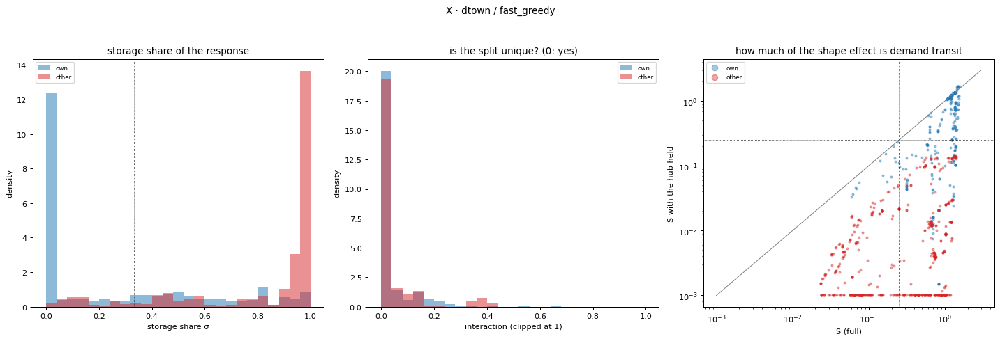

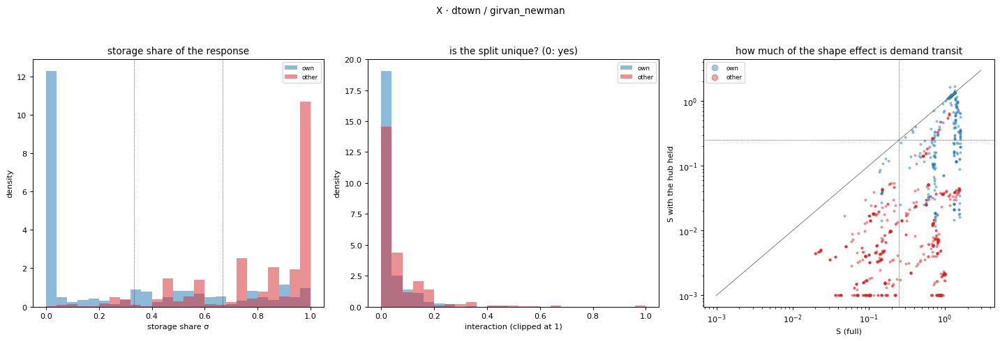

In [8]:
# X. demand / storage split on the probe drift (E2): storage share, its uniqueness, the shape left with the hub held
xs = LF[LF["g_tot"].abs() >= 1e-3].copy()
xs["S_kept"] = xs["S_de0"] / xs["S"].where(xs["S"] >= FLOOR["S"])
rows = []
for (p, own, tp_, ch), g in xs.groupby(["part", "own", "topo", "channel_S"], dropna=False):
    rows.append({"part": p, "own": own, "topo": tp_, "channel (S)": ch, "cells": len(g),
                 "median σ": g["sigma"].median(), "q90 σ": g["sigma"].quantile(0.9),
                 "σ undefined": float(g["sigma"].isna().mean()),
                 "median interaction": g["interaction"].median(), "q90 interaction": g["interaction"].quantile(0.9),
                 "shape kept with hub held (median S_de0 / S)": g["S_kept"].median()})
display(Markdown("**Channels** (candidate links × districts with |g_tot| ≥ 1e-3, final window). σ = |g_ie0| / (|g_de0| + "
                 "|g_ie0|), undefined below `sigma_floor`; interaction = |g_de1 − g_de0| on the same scale (large: the split "
                 "depends on which course the hub is held on, so σ is not unique); shape kept = S of the demand channel "
                 "alone over S. Channel (S): none below the S floor, else by σ."))
display(pd.DataFrame(rows).set_index(["part", "own", "topo", "channel (S)"]).round(3))
for p in PARTS:
    q_ = xs[xs["part"] == p]
    fig, axes = plt.subplots(1, 3, figsize=(16, 5.5))
    for own, cc in ((True, "#1f77b4"), (False, "#d62728")):
        g = q_[q_["own"] == own]
        lab_ = "own" if own else "other"
        axes[0].hist(g["sigma"].dropna(), bins=np.linspace(0, 1, 26), alpha=0.5, color=cc, density=True, label=lab_)
        axes[1].hist(g["interaction"].dropna().clip(0, 1), bins=np.linspace(0, 1, 26), alpha=0.5, color=cc, density=True,
                     label=lab_)
        axes[2].scatter(g["S"].clip(1e-3), g["S_de0"].clip(1e-3), s=5, alpha=0.4, color=cc, label=lab_)
    axes[0].axvline(CH_LO, color="k", lw=0.6, ls=":"); axes[0].axvline(CH_HI, color="k", lw=0.6, ls=":")
    axes[0].set(xlabel="storage share σ", ylabel="density", title="storage share of the response")
    axes[1].set(xlabel="interaction (clipped at 1)", ylabel="density", title="is the split unique? (0: yes)")
    axes[2].plot([1e-3, 3], [1e-3, 3], color="0.5", lw=0.8)
    axes[2].axhline(FLOOR["S"], color="k", lw=0.6, ls=":"); axes[2].axvline(FLOOR["S"], color="k", lw=0.6, ls=":")
    axes[2].set(xscale="log", yscale="log", xlabel="S (full)", ylabel="S with the hub held",
                title="how much of the shape effect is demand transit")
    for ax in axes:
        ax.legend(fontsize=7, markerscale=3)
    fig.suptitle(f"X · {p}"); fig.tight_layout(rect=(0, 0, 1, 0.94)); plt.show()

## M · Composition as a mixture descriptor (E1)

**M1** how mixed each link's water is (own share, $e^H$, districts holding ≥ `M_FLOOR`, water filling tanks) and where
the placed sensors' water goes. **M2** stability — the hour-of-week swing of the own share (alternation), flow
reversals, and how much the no-drift composition differs between the baseline window and each k's settled window.
**M3** power — does carrying $k$'s water ($m_k$), or its change under $k$'s drift ($\Delta m_k$), predict the exact
dependence on $k$?

**M1 · How mixed is each link's water?** (no-drift city, baseline window; candidate links) — share of its own district, effective number of districts $e^{H}$, districts holding ≥ 5%, share of its water filling tanks

links  m_home_med  m_home_q10  n_eff_med  mixed_share  tank_water_med  tank_water_q90
part                  topo                                                                                                
dtown / fast_greedy   branch           134       1.000       1.000      1.000        0.000           0.000           0.000
                      loop             239       1.000       0.150      1.000        0.259           0.259           0.531
                      source_bridge     49       0.974       0.286      1.128        0.449           0.504           0.690
dtown / girvan_newman branch           131       1.000       1.000      1.000        0.000           0.000           0.000
                      loop             240       1.000       0.408      1.000        0.371           0.241           0.587
                      source_bridge     49       0.744       0.263      1.767        0.673           0.522           0.616

placed sensors

sensors  m_home_med  n_eff_med  mixed
part                  slot_class                                       
dtown / fast_greedy   branch           10    1.000000   1.000000      0
                      transit          10    0.397067   1.912395      7
dtown / girvan_newman branch           10    1.000000   1.000000      0
                      transit          10    0.639357   1.922329      7

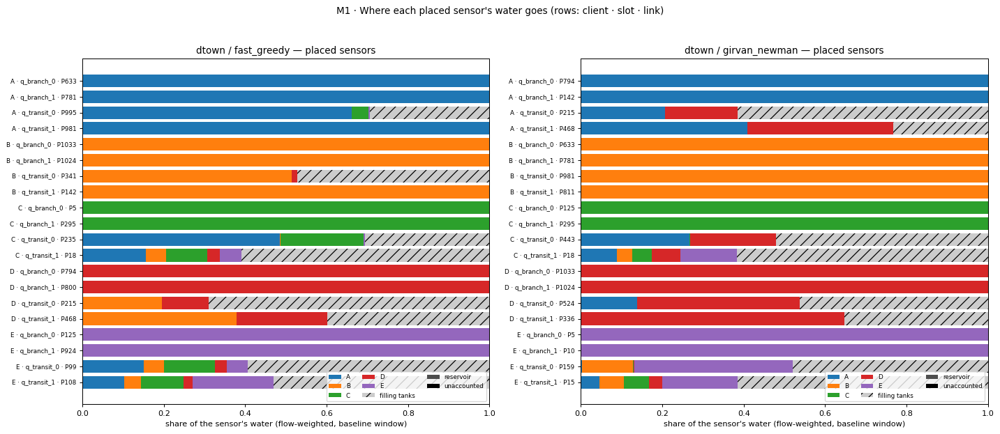

**M2 · Is the descriptor stable?** Hour-of-week swing of the own share (q95 − q05 over the 7·24 hours, district-renormalised; 0 = the same mix every hour, ≈ 1 = the pipe alternates between own and foreign water), flow reversals, and the change of the no-drift composition between the baseline window and each k's settled window (½‖Δm‖₁; the city is stationary, so this is how window-dependent the descriptor is)

links  swing_med  swing_q90  swing_max  flip_med  with_reversals
part                  topo                                                                           
dtown / fast_greedy   branch           134      0.000      0.000      0.000      0.00               0
                      loop             239      0.000      0.969      1.000      0.00              71
                      source_bridge     49      0.186      0.978      0.990      0.00              22
dtown / girvan_newman branch           131      0.000      0.000      0.000      0.00               0
                      loop             240      0.000      0.892      0.996      0.00              91
                      source_bridge     49      0.441      0.980      1.000      0.03              27

count  50%     90%     99%     max
part                  k_window                                      
dtown / fast_greedy   District_A  422.0  0.0  0.0026  0.0080  0.0083
                      District_B  422.0  0.0  0.0032  0.0072  0.0089
                      District_C  422.0  0.0  0.0032  0.0067  0.0093
                      District_D  422.0  0.0  0.0036  0.0061  0.0097
                      District_E  422.0  0.0  0.0036  0.0064  0.0102
dtown / girvan_newman District_A  420.0  0.0  0.0027  0.0090  0.0091
                      District_B  420.0  0.0  0.0025  0.0079  0.0081
                      District_C  420.0  0.0  0.0021  0.0056  0.0057
                      District_D  420.0  0.0  0.0019  0.0054  0.0056
                      District_E  420.0  0.0  0.0024  0.0060  0.0061

**M3 · Power: does the composition tell which drifts a link depends on?** (off-diagonal, final window; m_k = k's share of the link's water without drift, baseline window; Δm_k = its change under k's drift)

cells  responding  AUC m_k  AUC |dm_k|  P(responds | m_k >= 0.05)  P(responds | m_k < 0.01)  share of responding cells with m_k < 0.01  Spearman m_k vs S  Spearman |dm_k| vs S
part                  response                                                                                                                                                                                   
dtown / fast_greedy   S >= 0.25    1688         416    0.882       0.882                      0.995                     0.111                                      0.377              0.697                 0.695
                      Nr >= 0.05   1688         468    0.847       0.848                      0.962                     0.159                                      0.483              0.697                 0.695
dtown / girvan_newman S >= 0.25    1680         372    0.957       0.963                      1.000                     0.043                                      0.156              0.731                 0.743
                      Nr >= 0.05   1680         412    0.886       0.887                      0.996                     0.087                                      0.289              0.731                 0.743

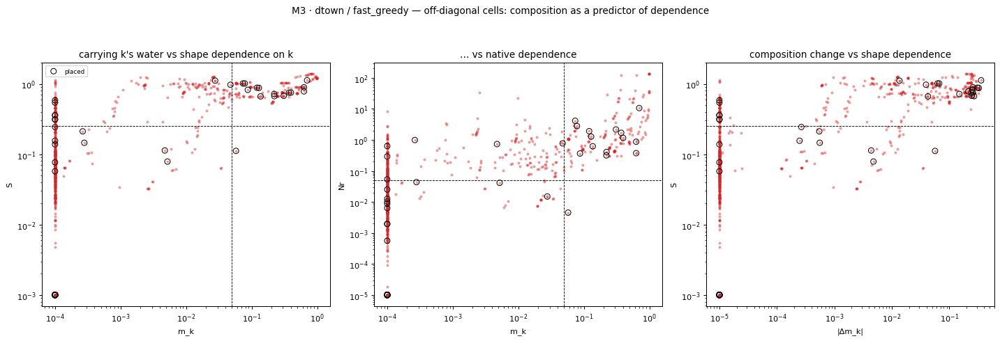

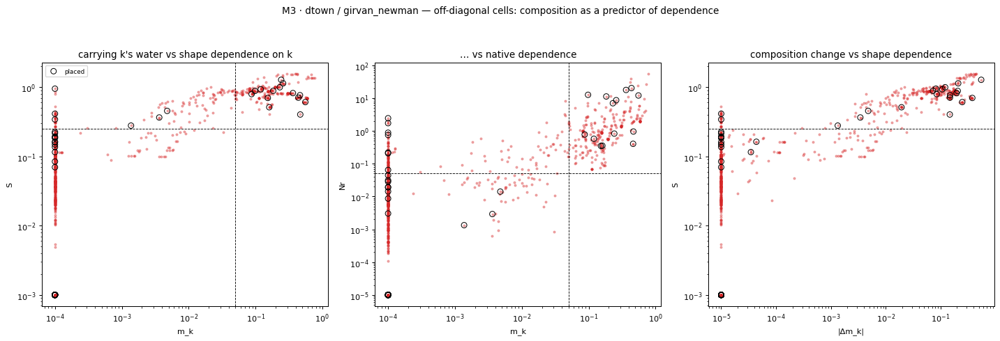

In [9]:
# M1-M3. composition (E1): how mixed each link's water is, how stable that is, and whether it predicts dependence
base = CAND.copy()
mcols = [f"m_{d}" for d in DISTS if f"m_{d}" in base.columns]
Mx = np.nan_to_num(base[mcols].to_numpy(float))
base["n_users"] = (Mx >= M_FLOOR).sum(axis=1)
display(Markdown(f"**M1 · How mixed is each link's water?** (no-drift city, baseline window; candidate links) — share of "
                 f"its own district, effective number of districts $e^{{H}}$, districts holding ≥ {M_FLOOR:.0%}, share "
                 "of its water filling tanks"))
display(base.groupby(["part", "topo"]).agg(
    links=("element", "size"), m_home_med=("m_home", "median"), m_home_q10=("m_home", lambda x: x.quantile(0.1)),
    n_eff_med=("n_eff", "median"), mixed_share=("n_users", lambda x: (x >= 2).mean()),
    tank_water_med=("c_storage", "median"), tank_water_q90=("c_storage", lambda x: x.quantile(0.9))).round(3))
display(Markdown("placed sensors"))
pl_ = base[base["placed"].astype(bool)]
if len(pl_):
    display(pl_.groupby(["part", "slot_class"]).agg(sensors=("element", "size"), m_home_med=("m_home", "median"),
                                                     n_eff_med=("n_eff", "median"), mixed=("n_users", lambda x: int((x >= 2).sum()))))
    dest = [d for d in DISTS if d in CMP.columns] + ["storage", "reservoir", "unaccounted"]
    fig, axes = plt.subplots(1, len(PARTS), figsize=(8 * len(PARTS), 7), squeeze=False)
    for j, p in enumerate(PARTS):
        ax = axes[0, j]
        q_ = CMP[(CMP["part"] == p) & (CMP["world"] == "nodrift") & (CMP["window"] == "baseline")]
        q_ = q_[q_["element"].isin(PLACED[p])].merge(base[base["part"] == p][["element", "home", "slot"]], on="element")
        q_ = q_.sort_values(["home", "slot"])
        y = np.arange(len(q_)); left = np.zeros(len(q_))
        for d in dest:
            v = np.nan_to_num(q_[d].to_numpy(float))
            col = DCOL.get(d, {"storage": "0.8", "reservoir": "0.3", "unaccounted": "k"}.get(d))
            ax.barh(y, v, left=left, color=col, hatch="//" if d == "storage" else None,
                    label=short(d) if d in DCOL else ("filling tanks" if d == "storage" else d))
            left += v
        ax.set_yticks(y, [f"{short(h)} · {s} · {e}" for h, s, e in zip(q_["home"], q_["slot"], q_["element"])], fontsize=7)
        ax.invert_yaxis()
        ax.set(xlim=(0, 1), xlabel="share of the sensor's water (flow-weighted, baseline window)", title=f"{p} — placed sensors")
        ax.legend(fontsize=7, ncol=3, loc="lower right")
    fig.suptitle("M1 · Where each placed sensor's water goes (rows: client · slot · link)")
    fig.tight_layout(rect=(0, 0, 1, 0.95)); plt.show()

display(Markdown("**M2 · Is the descriptor stable?** Hour-of-week swing of the own share (q95 − q05 over the 7·24 hours, "
                 "district-renormalised; 0 = the same mix every hour, ≈ 1 = the pipe alternates between own and foreign "
                 "water), flow reversals, and the change of the no-drift composition between the baseline window and each "
                 "k's settled window (½‖Δm‖₁; the city is stationary, so this is how window-dependent the descriptor is)"))
display(base.groupby(["part", "topo"]).agg(
    links=("element", "size"), swing_med=("swing_renorm", "median"), swing_q90=("swing_renorm", lambda x: x.quantile(0.9)),
    swing_max=("swing_renorm", "max"), flip_med=("flip_share", "median"),
    with_reversals=("flip_share", lambda x: int((x > 0).sum()))).round(3))
ST = TB["stationarity"]
if len(ST):
    display(ST.groupby(["part", "k_window"])["L1 baseline vs settled"].describe(percentiles=[0.5, 0.9, 0.99])[
        ["count", "50%", "90%", "99%", "max"]].round(4))

display(Markdown("**M3 · Power: does the composition tell which drifts a link depends on?** (off-diagonal, final window; "
                 "m_k = k's share of the link's water without drift, baseline window; Δm_k = its change under k's drift)"))
display(TB["m3"].set_index(["part", "response"]).drop(columns=["network", "partition"]).round(3))
for p in PARTS:
    xo = LF[(LF["part"] == p) & ~LF["own"]].dropna(subset=["m_k"])
    fig, axes = plt.subplots(1, 3, figsize=(16, 5.5))
    axes[0].scatter(xo["m_k"].clip(1e-4), xo["S"].clip(1e-3), s=5, alpha=0.35, color="#d62728")
    axes[1].scatter(xo["m_k"].clip(1e-4), xo["Nr"].clip(1e-5), s=5, alpha=0.35, color="#d62728")
    axes[2].scatter(xo["dm_k"].abs().clip(1e-5), xo["S"].clip(1e-3), s=5, alpha=0.35, color="#d62728")
    pl = xo[xo["placed"].astype(bool)]
    for ax, (xc, yc, lo) in zip(axes, (("m_k", "S", 1e-4), ("m_k", "Nr", 1e-4), ("dm_k", "S", 1e-5))):
        ax.scatter(pl[xc].abs().clip(lo), pl[yc].clip(1e-5 if yc == "Nr" else 1e-3), s=40, facecolors="none",
                   edgecolors="k", lw=0.8, label="placed")
        ax.axhline(FLOOR[yc], color="k", lw=0.7, ls="--")
        ax.set(xscale="log", yscale="log", xlabel=("|Δm_k|" if xc == "dm_k" else "m_k") , ylabel=yc)
    axes[0].axvline(M_FLOOR, color="k", lw=0.7, ls="--"); axes[1].axvline(M_FLOOR, color="k", lw=0.7, ls="--")
    axes[0].set_title("carrying k's water vs shape dependence on k"); axes[1].set_title("… vs native dependence")
    axes[2].set_title("composition change vs shape dependence"); axes[0].legend(fontsize=7)
    fig.suptitle(f"M3 · {p} — off-diagonal cells: composition as a predictor of dependence")
    fig.tight_layout(rect=(0, 0, 1, 0.93)); plt.show()

### M4 · Composition of every link, per client

One bar per candidate link homed in the client, **unnormalised**: the share of the water passing the link that ends in
each district's consumers (colours), in a filling tank (hatched), or elsewhere (reservoir inflow, solver residue; dark),
flow-weighted over the window — the bar sums to 1. ▼ placed sensor. Bars keep the no-drift order (own share) in every
figure, so in a drift figure a bar out of order is a link whose mix that drift changed. First all links per client
(no-drift city, baseline window); then by topological class for the no-drift city and each drifting district's world
(k's settled window).

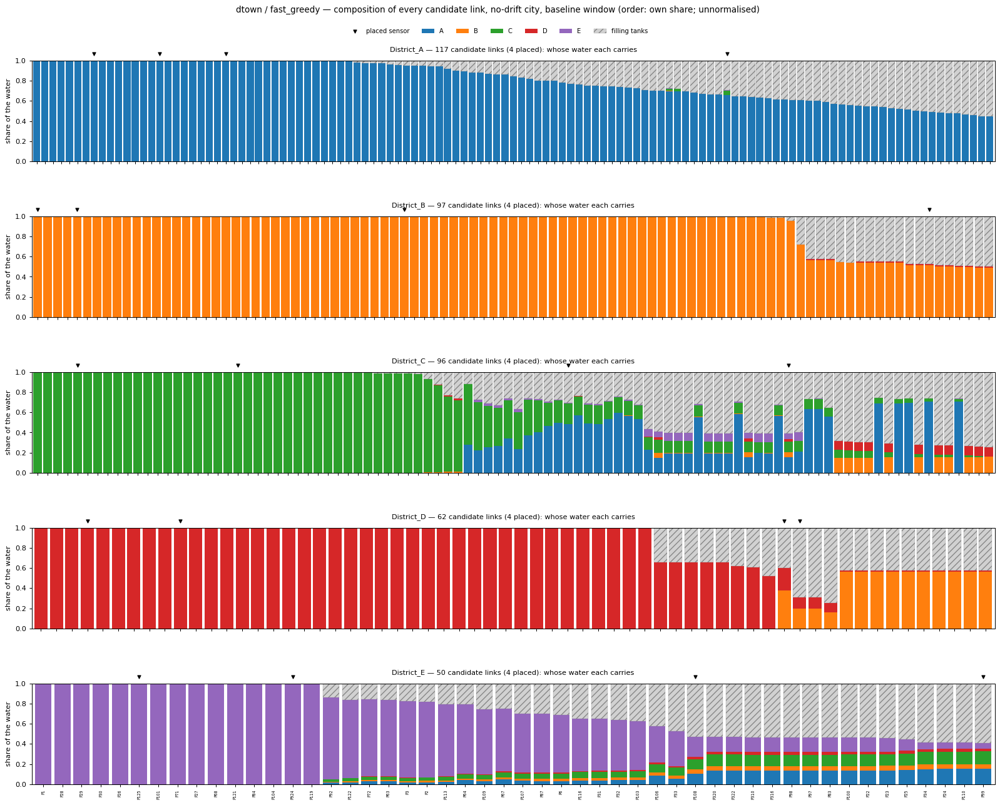

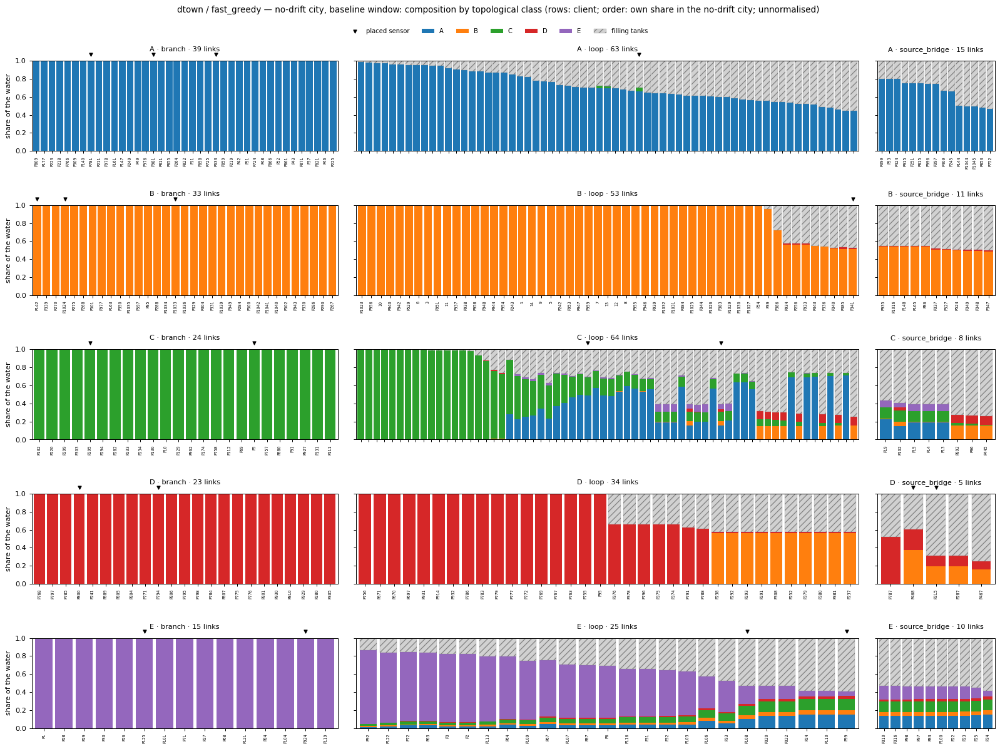

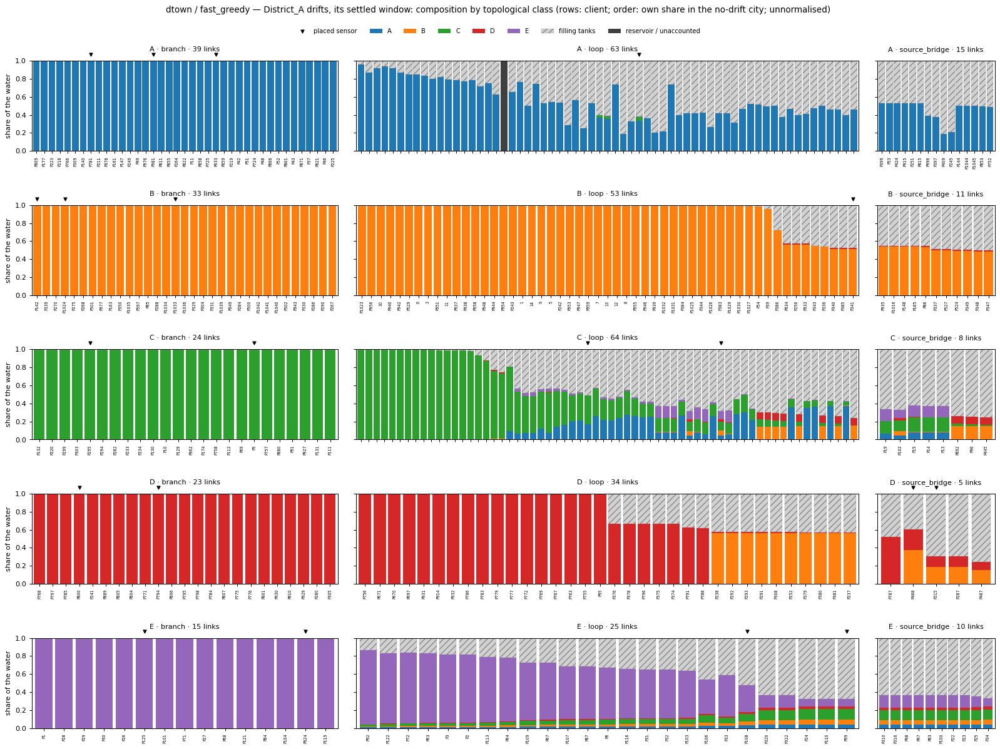

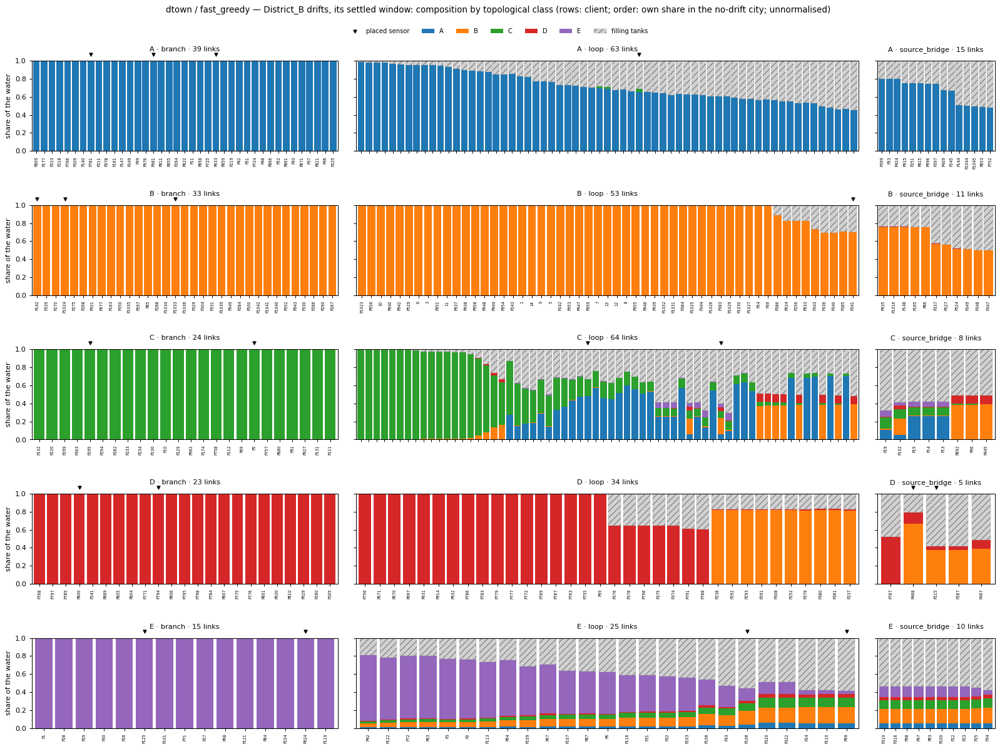

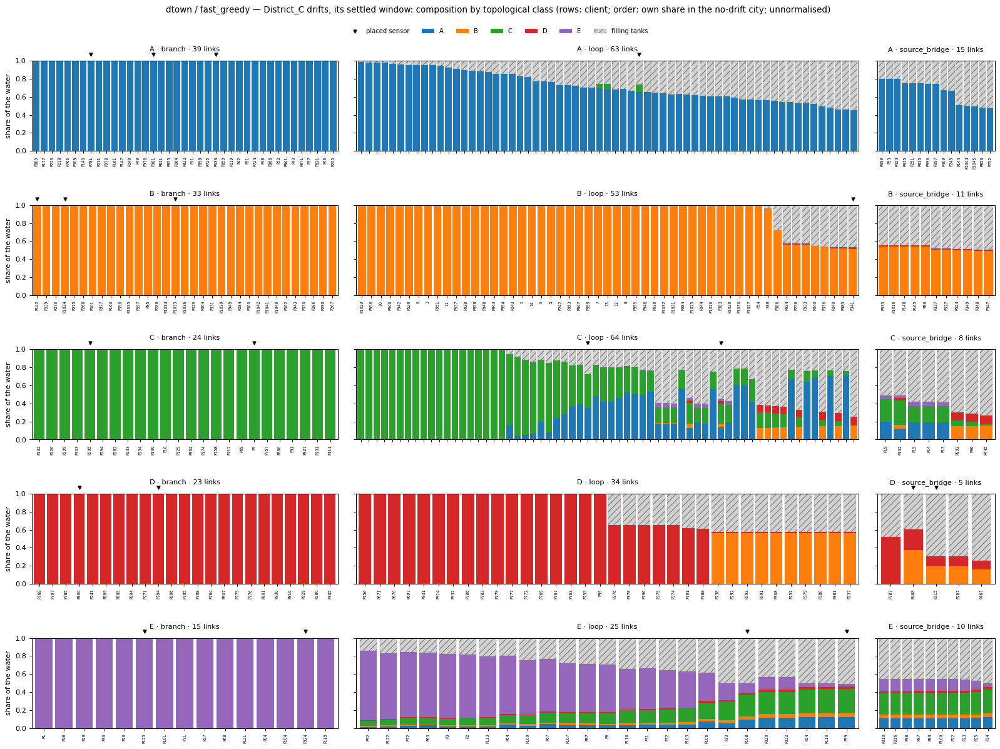

...

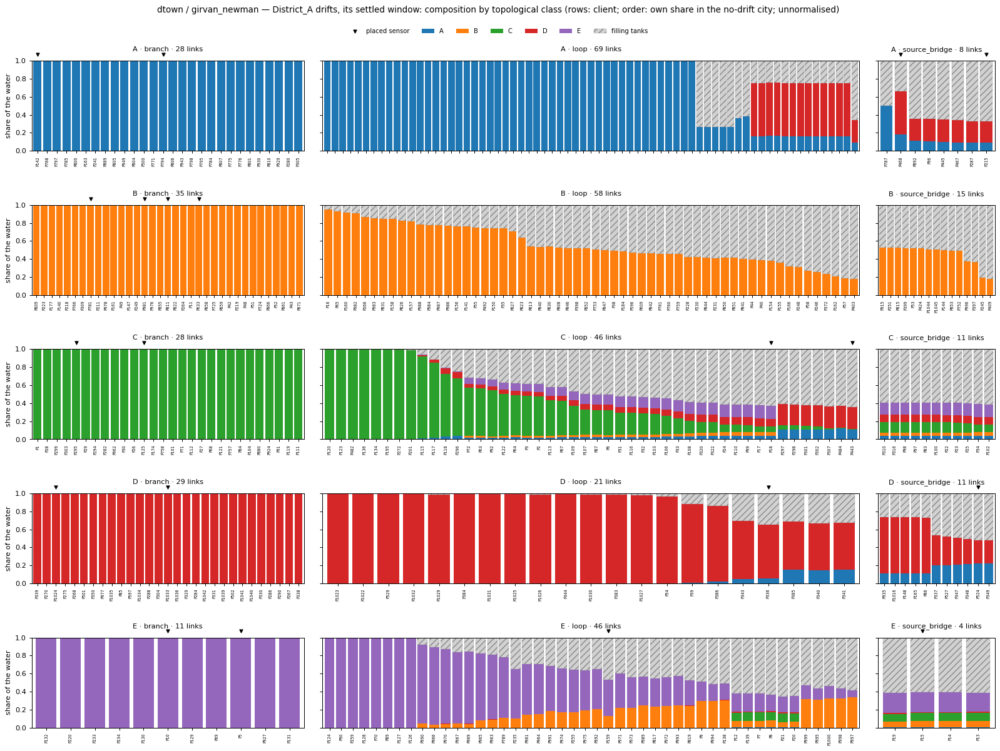

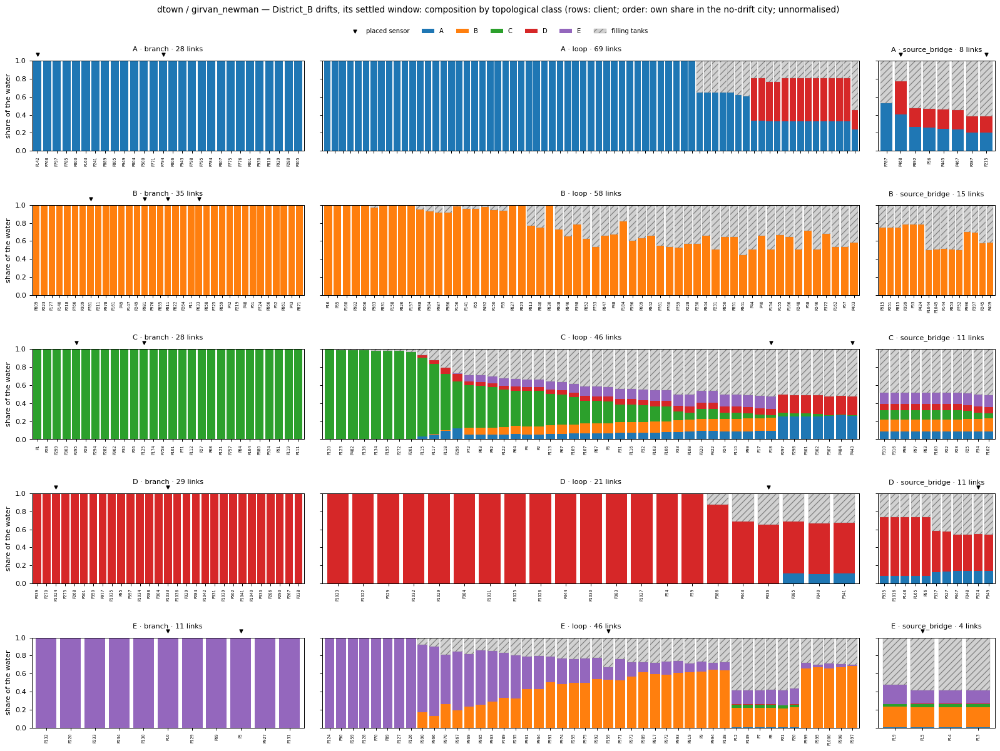

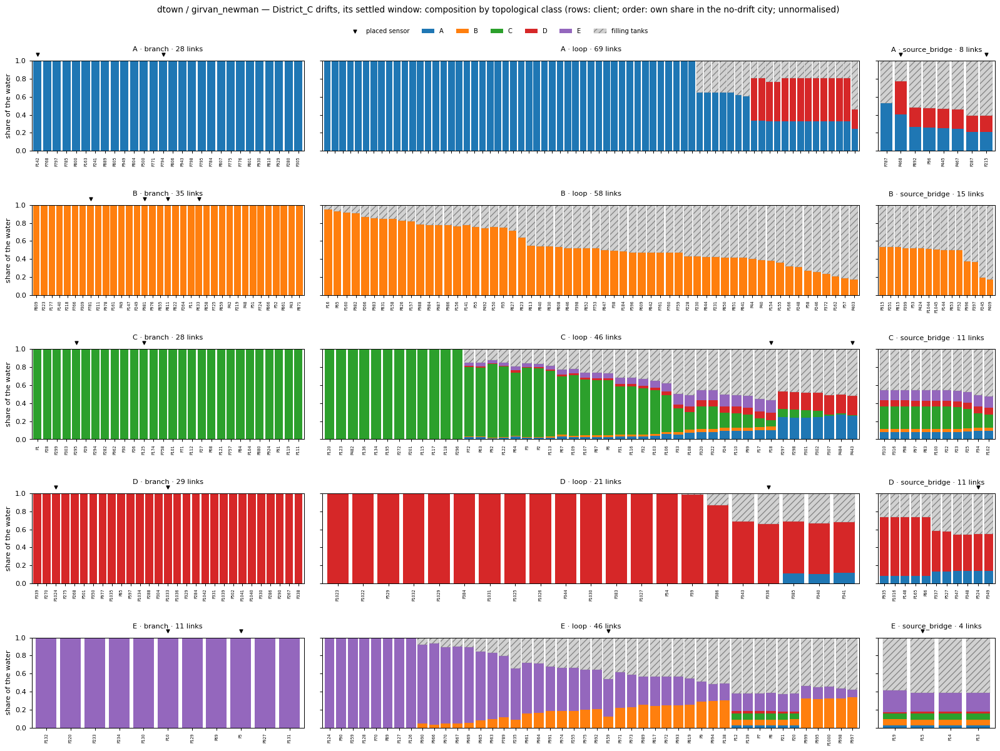

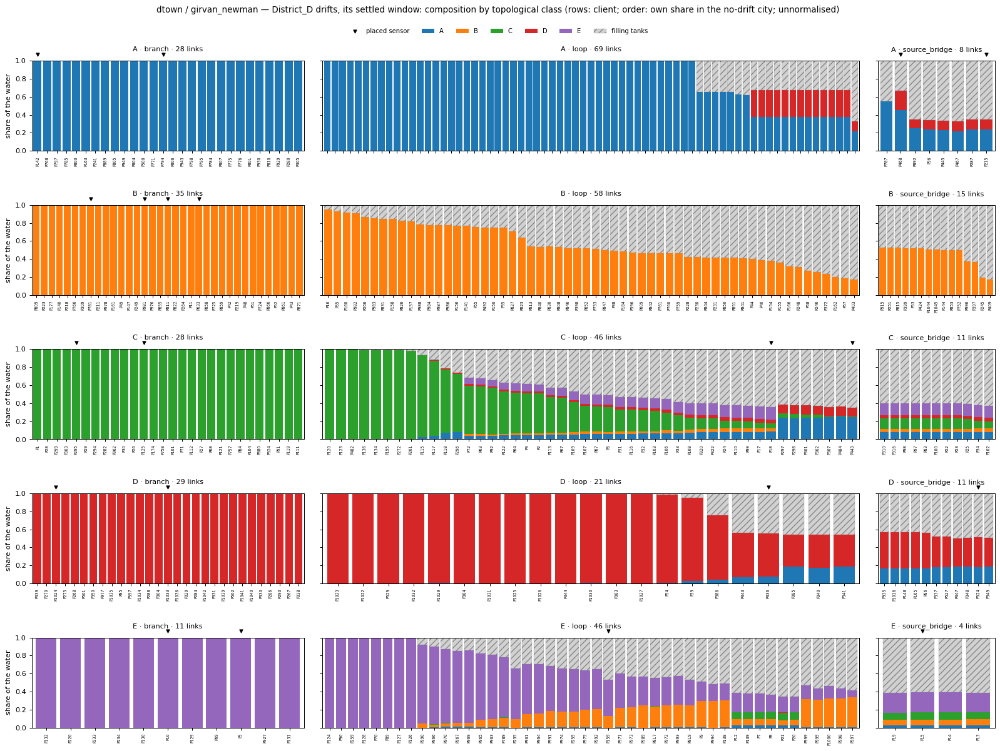

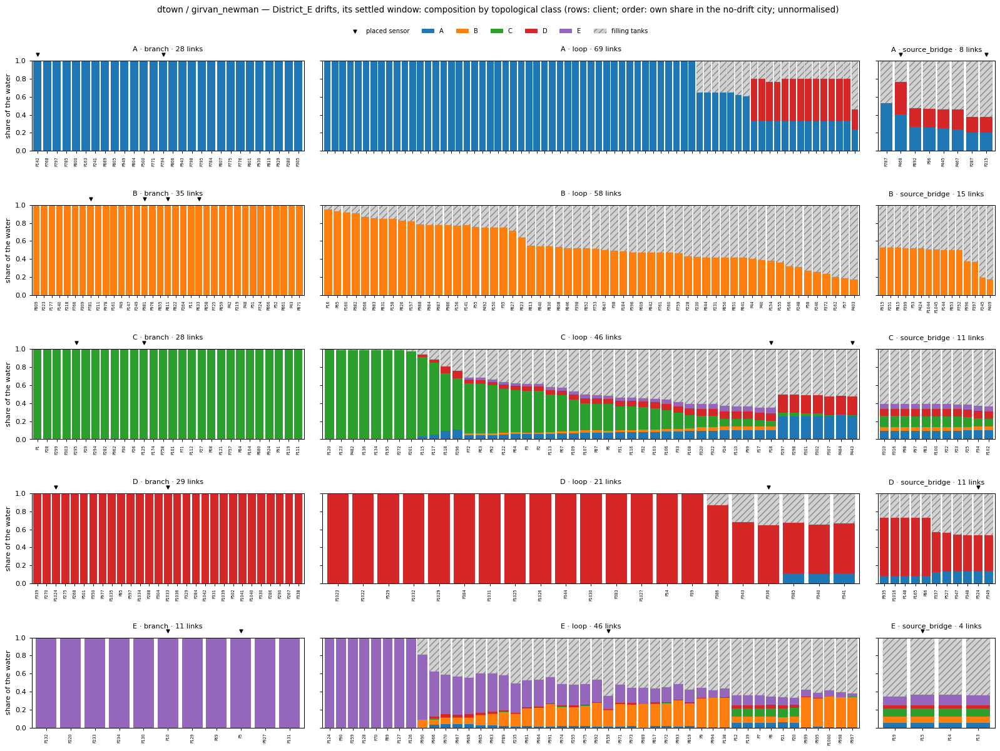

In [10]:
# M4. composition of every candidate link per client, unnormalised: the share of the water passing the link that ends in
#     each district's consumers, in filling tanks, or elsewhere (reservoir inflow, solver residue). No-drift city
#     (baseline window), then each drift world (k's settled window) by topological class. Order: own share, no drift
RAWD = [d for d in DISTS if d in CMP.columns]


def comp_bars(ax, q_, title):
    x = np.arange(len(q_))
    bottom = np.zeros(len(q_))
    for d in RAWD:
        v = np.nan_to_num(q_[d].to_numpy(float))
        ax.bar(x, v, bottom=bottom, width=0.85, color=DCOL[d], lw=0, label=short(d))
        bottom += v
    v = np.nan_to_num(q_["storage"].to_numpy(float))
    ax.bar(x, v, bottom=bottom, width=0.85, color="0.82", hatch="///", edgecolor="0.5", lw=0.2, label="filling tanks")
    bottom += v
    v = np.nan_to_num((q_["reservoir"] + q_["unaccounted"]).to_numpy(float))
    if (v > 1e-3).any():
        ax.bar(x, v, bottom=bottom, width=0.85, color="0.25", lw=0, label="reservoir / unaccounted")
    und = ~np.isfinite(q_[RAWD].to_numpy(float)).any(axis=1)
    if und.any():
        ax.bar(x[und], 1.0, width=0.85, color="0.93", lw=0, label="undefined (no flow)")
    pl = q_["placed"].to_numpy(bool)
    if pl.any():
        ax.scatter(x[pl], np.full(pl.sum(), 1.07), marker="v", s=16, color="k", clip_on=False, label="placed sensor")
    ax.set_xlim(-0.6, max(len(q_), 1) - 0.4); ax.set_ylim(0, 1)
    ax.set_xticks(x, list(q_["element"]) if len(q_) <= 60 else [""] * len(q_), rotation=90, fontsize=5)
    ax.set_title(title, fontsize=9, pad=12)


def top_legend(fig, axes, H, title):
    h_ = {}
    for ax in np.ravel(axes):
        for hh, ll in zip(*ax.get_legend_handles_labels()):
            h_.setdefault(ll, hh)
    fig.suptitle(title, y=1 - 0.12 / H)
    fig.legend(list(h_.values()), list(h_.keys()), loc="upper center", ncol=len(h_), fontsize=8, frameon=False,
               bbox_to_anchor=(0.5, 1 - 0.42 / H))


for p in PARTS:
    info = CAND[CAND["part"] == p][["element", "home", "topo", "placed"]].assign(placed=lambda d: d["placed"].astype(bool))
    b_ = CMP[(CMP["part"] == p) & (CMP["world"] == "nodrift") & (CMP["window"] == "baseline")].merge(info, on="element")
    b_["own_raw"] = [r[h] if h in b_.columns else np.nan for _, r in b_.iterrows() for h in [r["home"]]]
    order_of = b_.set_index("element")["own_raw"]
    by_own = lambda q_: q_.assign(_o=q_["element"].map(order_of)).sort_values(["_o", "element"], ascending=[False, True],
                                                                            na_position="last")
    homes = [d for d in DISTS if d in set(b_["home"])]
    H = 1.3 + 2.6 * len(homes)
    fig, axes = plt.subplots(len(homes), 1, figsize=(18, H), squeeze=False)
    for i_, h in enumerate(homes):
        r_ = by_own(b_[b_["home"] == h])
        comp_bars(axes[i_, 0], r_, f"{h} — {len(r_)} candidate links ({int(r_['placed'].sum())} placed): whose water each carries")
        axes[i_, 0].set_ylabel("share of the water")
    fig.subplots_adjust(top=1 - 1.1 / H, bottom=0.35 / H, left=0.04, right=0.99, hspace=0.55)
    top_legend(fig, axes, H, f"{p} — composition of every candidate link, no-drift city, baseline window "
                             "(order: own share; unnormalised)")
    plt.show()
    cases = [("no-drift city, baseline window", b_)]
    for k in sorted(CMP[(CMP["part"] == p) & (CMP["world"] == "drift")]["k"].dropna().unique()):
        cases.append((f"{k} drifts, its settled window",
                      CMP[(CMP["part"] == p) & (CMP["world"] == "drift") & (CMP["k"] == k)].merge(info, on="element")))
    wr = [max(1, int(b_[b_["topo"] == t].groupby("home").size().max())) if (b_["topo"] == t).any() else 1 for t in TOPOS]
    for tag, w_ in cases:
        H = 1.3 + 2.4 * len(homes)
        fig = plt.figure(figsize=(18, H))
        gs = fig.add_gridspec(len(homes), len(TOPOS), width_ratios=wr, hspace=0.6, wspace=0.06,
                              top=1 - 1.1 / H, bottom=0.35 / H, left=0.04, right=0.99)
        axes = np.empty((len(homes), len(TOPOS)), dtype=object)
        for i_, h in enumerate(homes):
            for j_, t in enumerate(TOPOS):
                ax = axes[i_, j_] = fig.add_subplot(gs[i_, j_])
                r_ = by_own(w_[(w_["home"] == h) & (w_["topo"] == t)])
                comp_bars(ax, r_, f"{short(h)} · {t} · {len(r_)} links")
                if j_ == 0:
                    ax.set_ylabel("share of the water")
                else:
                    ax.set_yticklabels([])
        top_legend(fig, axes, H, f"{p} — {tag}: composition by topological class (rows: client; order: own share in the "
                                 "no-drift city; unnormalised)")
        plt.show()

## T · The placed sensors' labels

Placed sensors × drifting district: Nr and S over init / transition / final, and the final γ_S, σ and composition; then
S and N month by month.

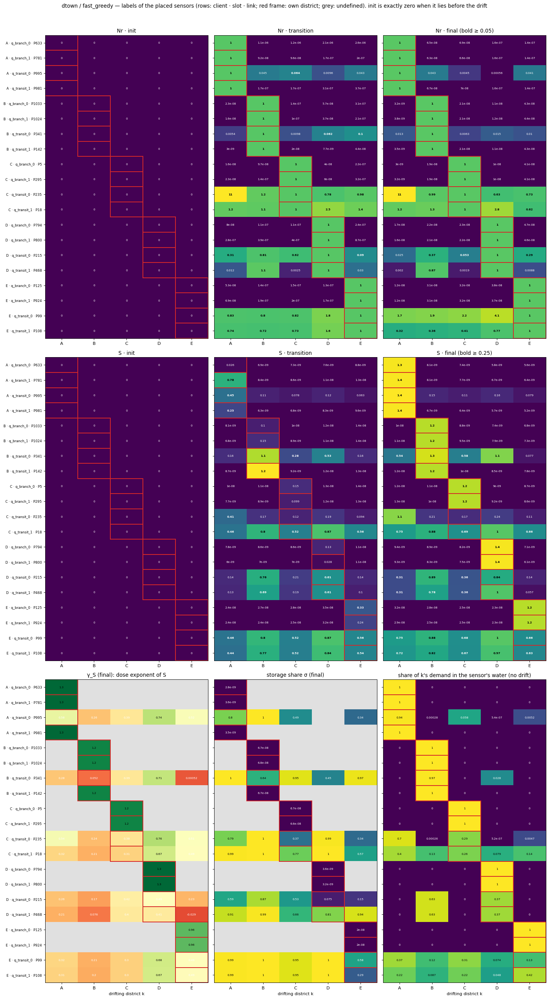

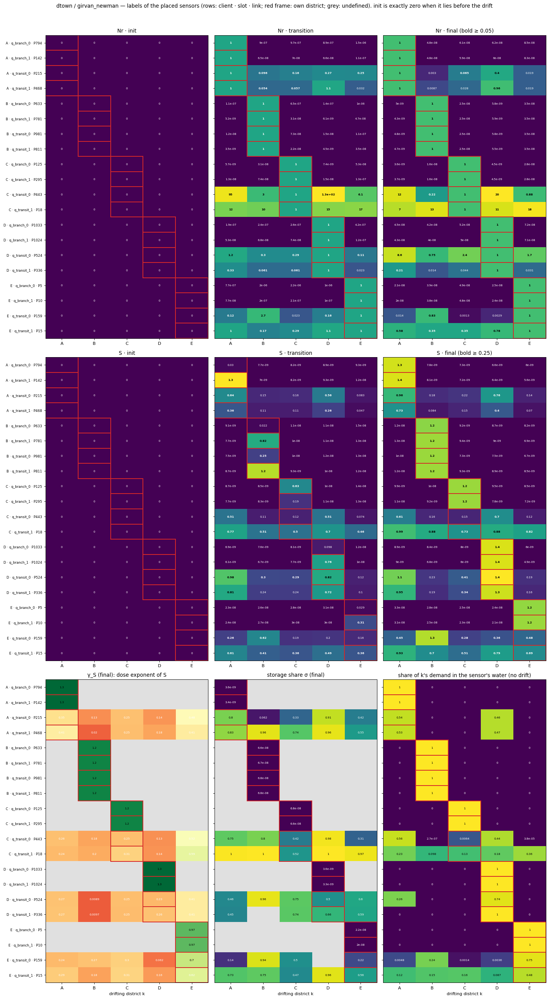

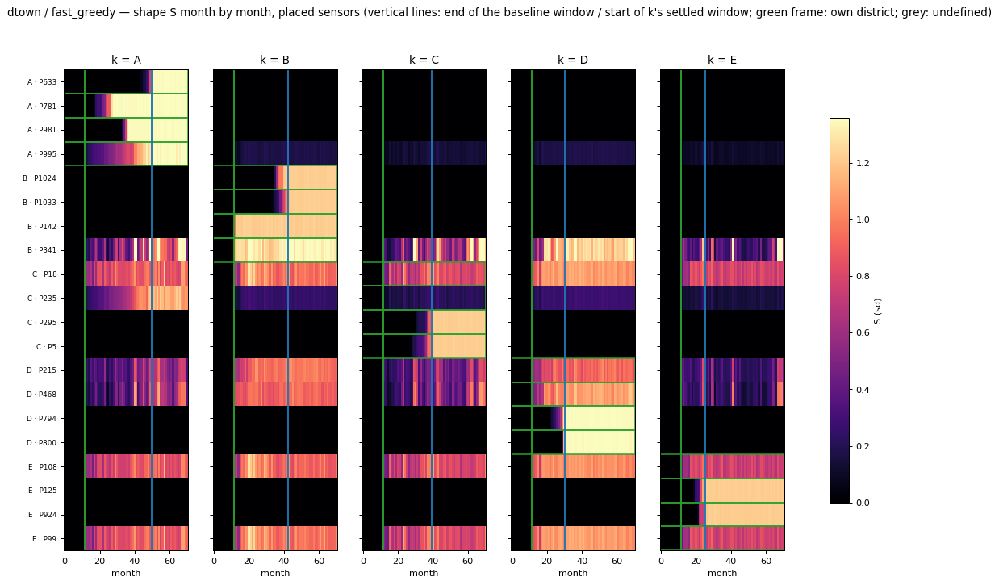

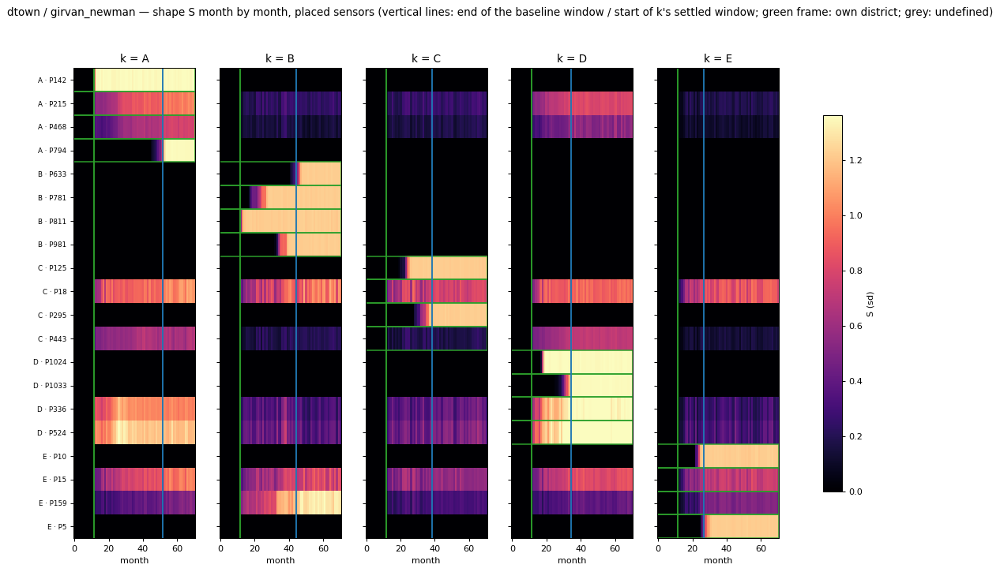

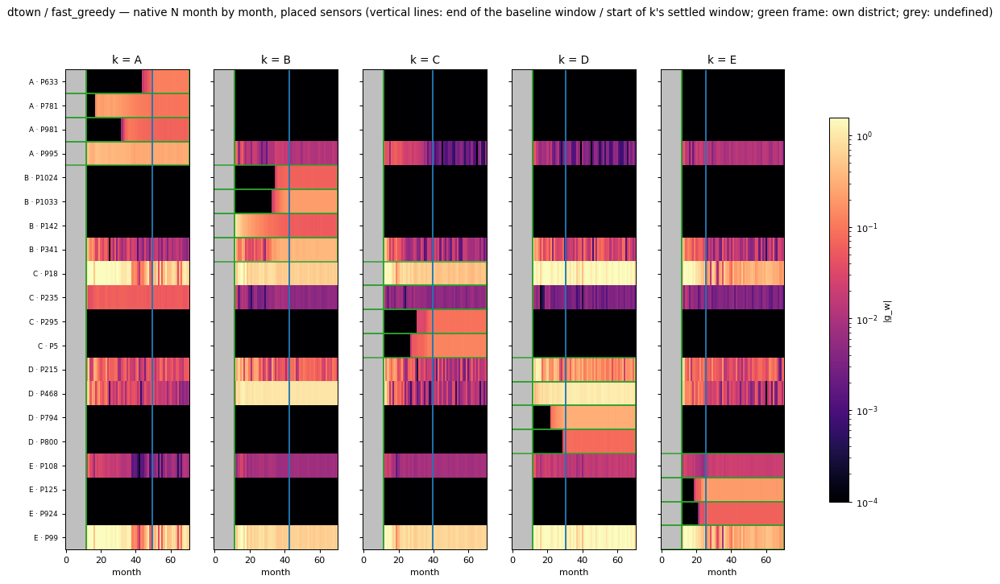

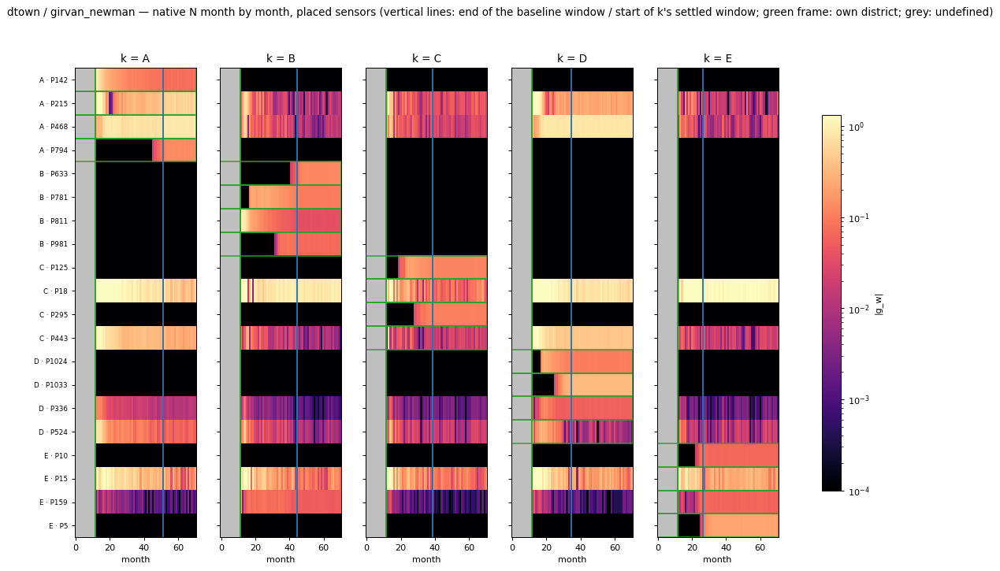

In [11]:
# T. the labels of the placed sensors over init / transition / final, and month by month
NORM = {"Nr": lambda v: LogNorm(vmin=1e-3, vmax=max(np.nanmax(v), 1.0)),
        "S": lambda v: plt.Normalize(vmin=0, vmax=max(np.nanmax(v), 0.5)),
        "gamma_S": lambda v: plt.Normalize(vmin=-0.25, vmax=1.25), "sigma": lambda v: plt.Normalize(0, 1),
        "m_k": lambda v: LogNorm(vmin=1e-3, vmax=1.0)}
TITLE = {"gamma_S": "γ_S (final): dose exponent of S", "sigma": "storage share σ (final)",
         "m_k": "share of k's demand in the sensor's water (no drift)"}
FIN = [c for c in (("gamma_S",) if DOSE else ()) + ("sigma", "m_k")]


def draw(ax, A, x, ks, hm, show_y, ylab):
    V = A.to_numpy(float)
    finite = V[np.isfinite(V)]
    nrm = NORM[x](finite if len(finite) else np.array([1.0]))
    lo_ = nrm.vmin
    Vp = np.where(np.isfinite(V), np.maximum(V, lo_), np.nan)
    cm = plt.get_cmap("RdYlGn" if x == "gamma_S" else "viridis").copy(); cm.set_bad("0.88")
    ax.imshow(np.ma.masked_invalid(Vp), aspect="auto", cmap=cm, norm=nrm, interpolation="nearest")
    for (a_, b_), v in np.ndenumerate(V):
        if np.isfinite(v):
            light = nrm(max(v, lo_)) > 0.6
            ax.text(b_, a_, "0" if v == 0 else f"{v:.2g}", ha="center", va="center", fontsize=6,
                    color="k" if light else "w", fontweight="bold" if (x in FLOOR and v >= FLOOR[x]) else "normal")
    for a_, h in enumerate(hm):
        if h in ks:
            ax.add_patch(plt.Rectangle((ks.index(h) - 0.5, a_ - 0.5), 1, 1, fill=False, ec="#d62728", lw=1.6))
    ax.set_xticks(range(len(ks)), [short(c) for c in ks])
    ax.set_yticks(range(len(hm)), ylab if show_y else [], fontsize=7)


TL = LBL[LBL["placed"].astype(bool)]
if not len(TL):
    display(Markdown("**T skipped**: no placed sensors (STACKS mode)."))
for p in [p for p in PARTS if p in set(TL["part"])]:
    q_ = TL[TL["part"] == p]
    rows_ = q_.drop_duplicates("element").merge(LKS[LKS["part"] == p][["element", "slot"]], on="element").sort_values(
        ["home", "slot"])
    order_e, hm = list(rows_["element"]), rows_["home"].tolist()
    ylab = [f"{short(h)} · {s} · {e}" for h, s, e in zip(hm, rows_["slot"], order_e)]
    ks = sorted(q_["k"].unique())
    pers = [x for x in ("init", "transition", "final") if x in set(q_["period"])]
    fig, axes = plt.subplots(3, 3, figsize=(16, 2.5 + 1.35 * len(order_e)), squeeze=False)
    for i, x in enumerate(("Nr", "S")):
        for j in range(3):
            if j >= len(pers):
                axes[i, j].axis("off"); continue
            per = pers[j]
            A = q_[q_["period"] == per].pivot_table(index="element", columns="k", values=x).reindex(index=order_e, columns=ks)
            draw(axes[i, j], A, x, ks, hm, j == 0, ylab)
            axes[i, j].set_title(f"{x} · {per}" + (f" (bold ≥ {FLOOR[x]:g})" if per == "final" else ""))
    for j in range(3):
        ax = axes[2, j]
        if j < len(FIN):
            x = FIN[j]
            A = q_[q_["period"] == "final"].pivot_table(index="element", columns="k", values=x).reindex(index=order_e, columns=ks)
            draw(ax, A, x, ks, hm, j == 0, ylab)
            ax.set_title(TITLE[x]); ax.set_xlabel("drifting district k")
        else:
            ax.axis("off")
    fig.suptitle(f"{p} — labels of the placed sensors (rows: client · slot · link; red frame: own district; grey: undefined). "
                 "init is exactly zero when it lies before the drift")
    fig.tight_layout(rect=(0, 0, 1, 0.97)); plt.show()

# month by month, placed sensors
for x, col in (("S", "S"), ("N", "g_w")):
    for p in [p for p in PARTS if p in set(TL["part"])]:
        q_ = MON[(MON["part"] == p) & MON["placed"].astype(bool)]
        if not len(q_):
            continue
        order_e = list(q_.drop_duplicates("element").sort_values(["home", "element"])["element"])
        hm_ = q_.drop_duplicates("element").set_index("element")["home"]
        ks = sorted(q_["k"].unique())
        vals = q_[col].abs()
        vmax = float(np.nanquantile(vals, 0.99)) if vals.notna().any() else 1.0
        fig, axes = plt.subplots(1, len(ks), figsize=(16, 2 + 0.33 * len(order_e)), squeeze=False, sharey=True)
        cm = plt.get_cmap("magma").copy(); cm.set_bad("0.75")
        for j, k in enumerate(ks):
            ax = axes[0, j]
            A = q_[q_["k"] == k].assign(v=lambda d: d[col].abs()).pivot_table(index="element", columns="month",
                                                                             values="v").reindex(order_e)
            im = ax.imshow(np.ma.masked_invalid(A.to_numpy(float)), aspect="auto", cmap=cm, interpolation="nearest",
                           norm=LogNorm(vmin=1e-4, vmax=max(vmax, 1e-3)) if x == "N" else plt.Normalize(0, vmax))
            for a_, e in enumerate(order_e):
                if hm_.get(e) == k:
                    ax.add_patch(plt.Rectangle((-0.5, a_ - 0.5), A.shape[1], 1, fill=False, ec="#2ca02c", lw=1.2))
            W = win_of(p, k)
            for edge, c in ((W["transition"][0] / W["sm"], "#2ca02c"), (W["final"][0] / W["sm"], "#1f77b4")):
                ax.axvline(edge - 0.5, color=c, lw=1.5)
            ax.set(title=f"k = {short(k)}", xlabel="month")
            if j == 0:
                ax.set_yticks(range(len(order_e)), [f"{short(hm_[e])} · {e}" for e in order_e], fontsize=7)
        fig.colorbar(im, ax=axes.ravel().tolist(), shrink=0.8, label=("|g_w|" if x == "N" else "S (sd)"))
        fig.suptitle(f"{p} — {('shape S' if x == 'S' else 'native N')} month by month, placed sensors (vertical lines: end of "
                     "the baseline window / start of k's settled window; green frame: own district; grey: undefined)")
        plt.show()

### T2 · Shape S month by month — every candidate link, clustered

Every candidate link, then each topological class on its own. Row order: Ward clustering of
$x_s=(S_{s,k,\mu})_{k,\mu}$ (all drifting districts × months; undefined counted as 0), optimal leaf ordering. Strips:
the link's client and placed sensors (black). One colour scale per partition (q99). Up to 80 rows: labels and green
own-district frames; above that only the strips.

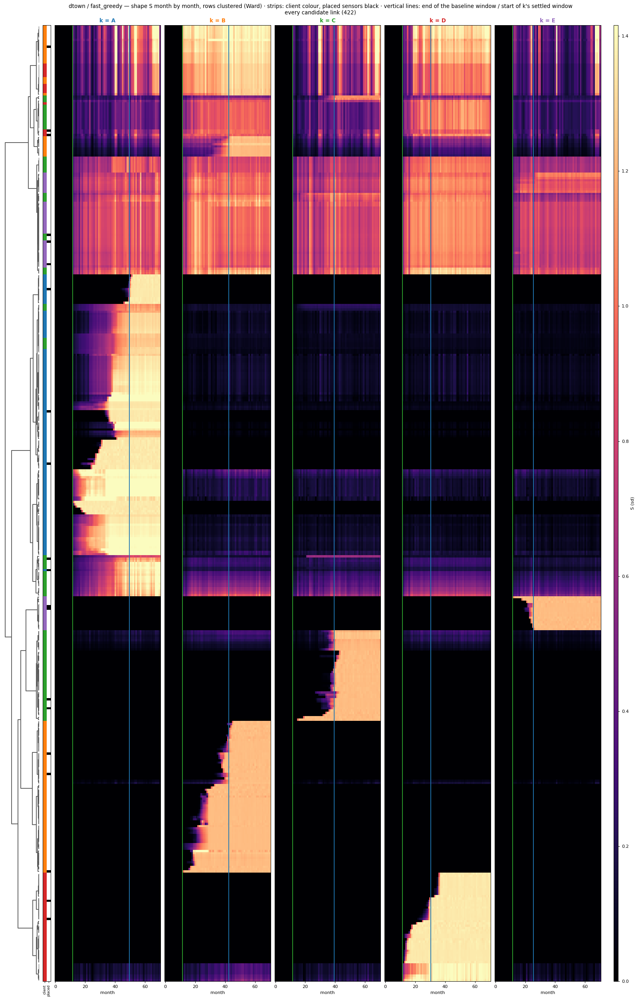

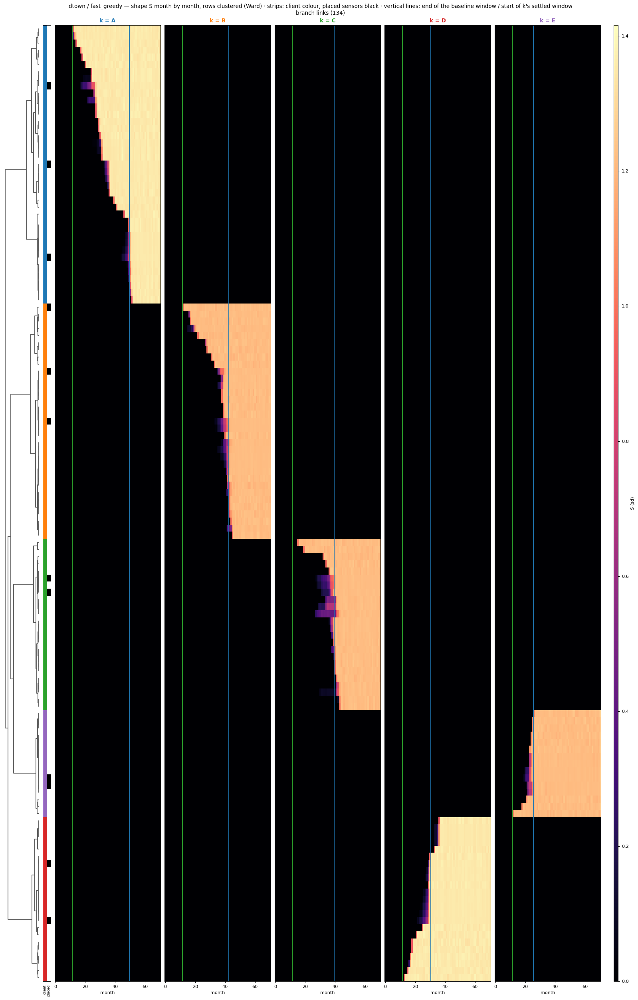

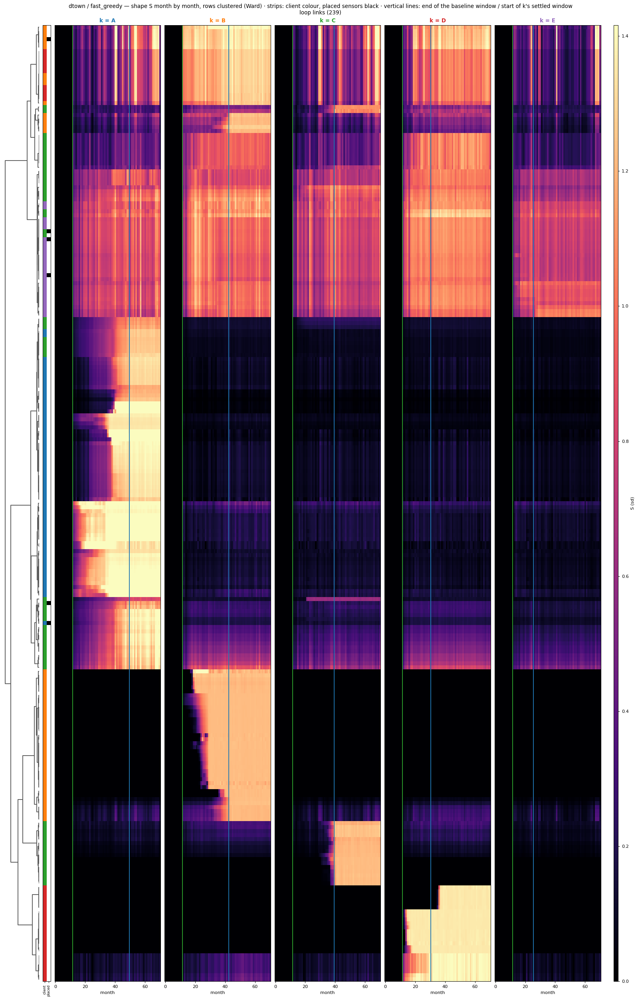

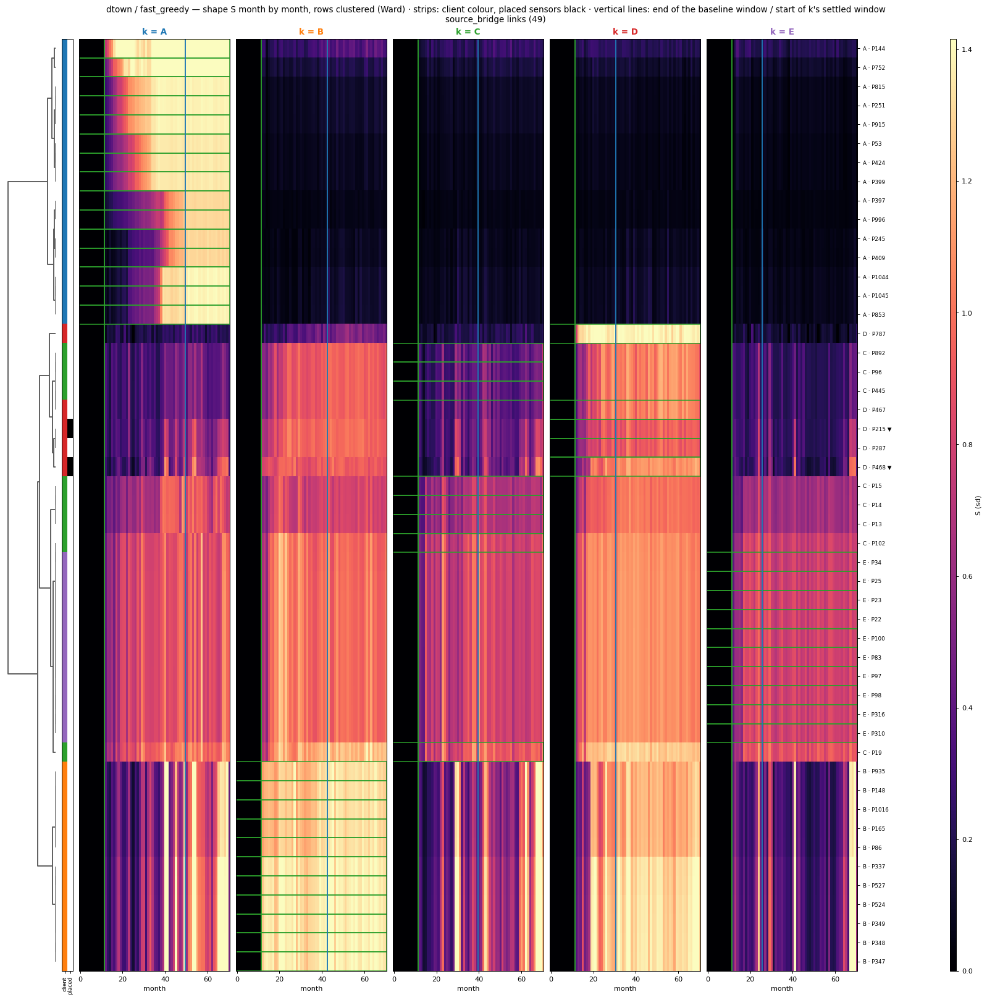

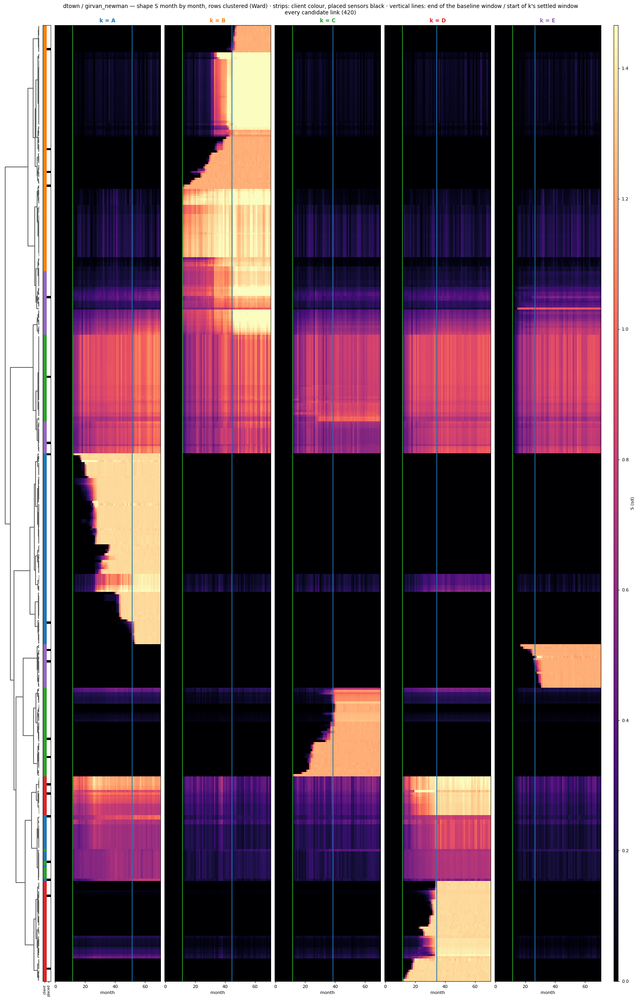

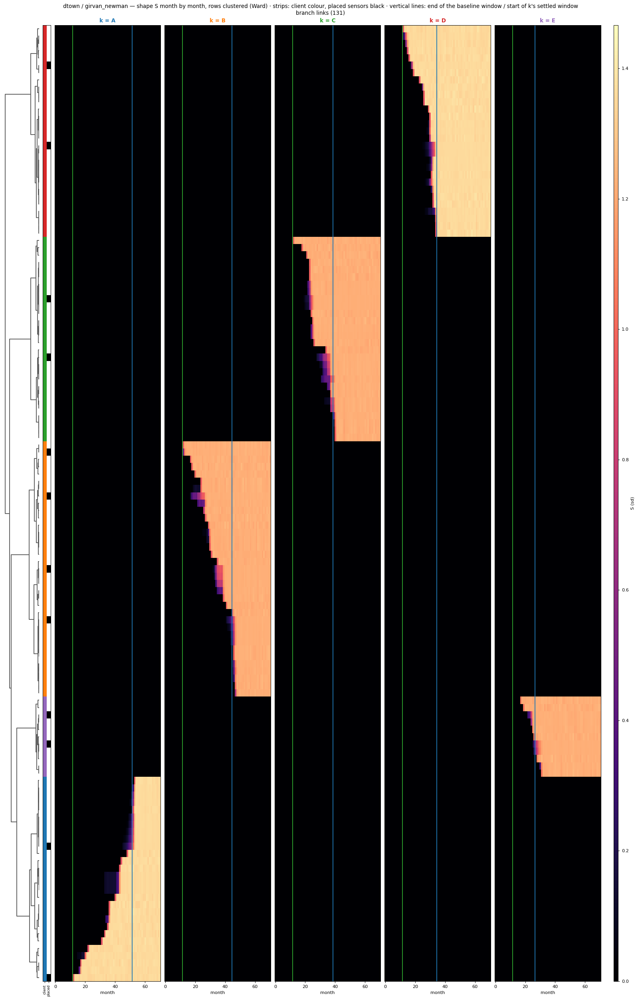

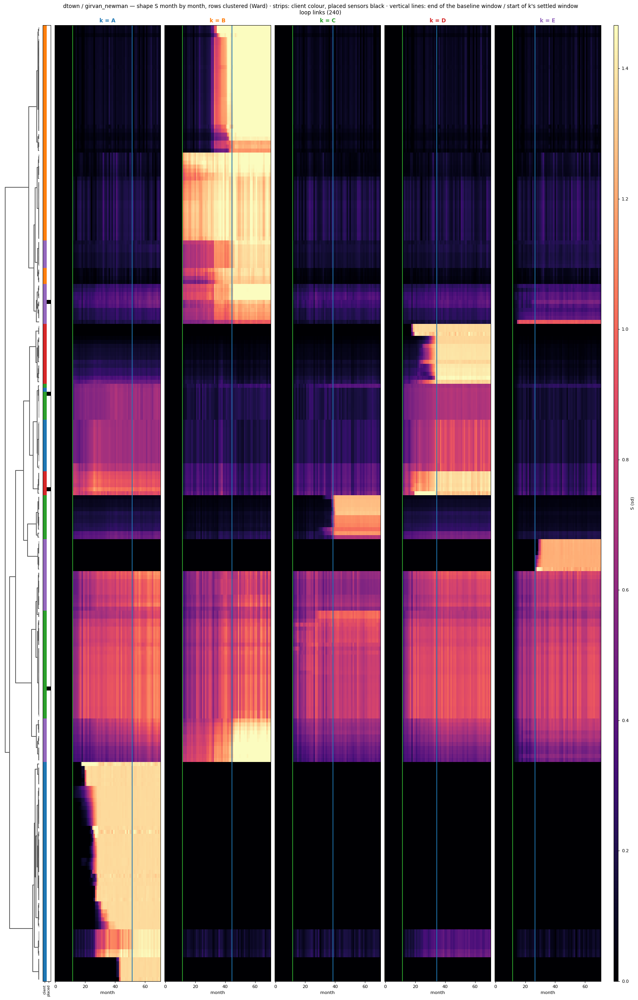

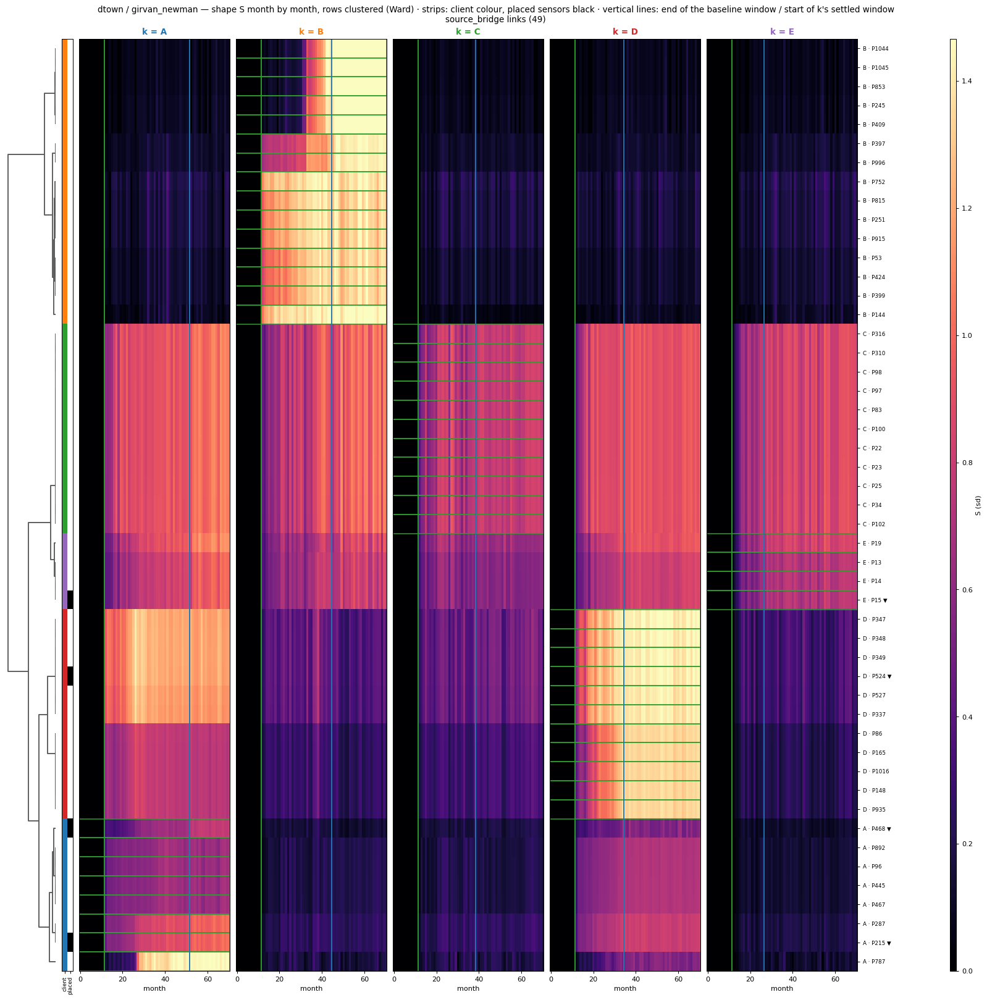

In [12]:
# T2. S month by month for every candidate link, then each topological class on its own; rows ordered by hierarchical
#     clustering of the whole k x month pattern
HC_LABELS = [("S", "S")]                    # add ("N", "g_w") for the native label


def hc_order(X):
    """Row order of X (rows x features; NaN counted as 0): Ward linkage on Euclidean distance, optimal leaf order."""
    if len(X) < 2:
        return np.arange(len(X)), None
    Z = linkage(np.nan_to_num(X), method="ward", optimal_ordering=True)
    return leaves_list(Z), Z


def month_hc(p, q_, col, norm, cbar_label, title):
    ks, months = sorted(q_["k"].unique()), sorted(q_["month"].unique())
    V = q_.assign(v=q_[col].abs()).set_index(["element", "k", "month"])["v"].unstack(["k", "month"])
    V = V.reindex(columns=pd.MultiIndex.from_product([ks, months]))
    order, Z = hc_order(V.to_numpy(float))
    V = V.iloc[order]
    info = q_.drop_duplicates("element").set_index("element").loc[V.index]
    n, show = len(V), len(V) <= 80
    H = 2.0 + min(0.33 * n, max(26.0, 0.04 * n), 40.0)
    fig = plt.figure(figsize=(18, H))
    gs = fig.add_gridspec(1, len(ks) + 4, width_ratios=[1.0, 0.22] + [3.0] * len(ks) + [1.6 if show else 0.15, 0.12],
                          wspace=0.06, top=1 - 0.8 / H, bottom=0.6 / H, left=0.01, right=0.96)
    axd, axs = fig.add_subplot(gs[0, 0]), fig.add_subplot(gs[0, 1])
    if Z is not None:
        dendrogram(Z, orientation="left", ax=axd, no_labels=True, color_threshold=0, above_threshold_color="0.35")
        axd.set_ylim(10 * n, 0)
    axd.axis("off")
    strip = np.ones((n, 2, 3))
    strip[:, 0] = [DCOL.get(h, (0.5, 0.5, 0.5, 1.0))[:3] for h in info["home"]]
    strip[info["placed"].to_numpy(bool), 1] = 0.0
    axs.imshow(strip, aspect="auto", interpolation="nearest")
    axs.set_xticks([0, 1], ["client", "placed"], rotation=90, fontsize=7); axs.set_yticks([])
    cm = plt.get_cmap("magma").copy(); cm.set_bad("0.75")
    for j, k in enumerate(ks):
        ax = fig.add_subplot(gs[0, 2 + j])
        im = ax.imshow(np.ma.masked_invalid(V[k].to_numpy(float)), aspect="auto", cmap=cm, interpolation="nearest",
                       norm=norm, extent=(months[0] - 0.5, months[-1] + 0.5, n - 0.5, -0.5))
        if show:
            for a_, h in enumerate(info["home"]):
                if h == k:
                    ax.add_patch(plt.Rectangle((months[0] - 0.5, a_ - 0.5), len(months), 1, fill=False, ec="#2ca02c", lw=1.2))
        W = win_of(p, k)
        for edge, c in ((W["transition"][0] / W["sm"], "#2ca02c"), (W["final"][0] / W["sm"], "#1f77b4")):
            ax.axvline(edge - 0.5, color=c, lw=1.5)
        ax.set_title(f"k = {short(k)}", color=DCOL.get(k, "k"), fontweight="bold"); ax.set_xlabel("month"); ax.set_yticks([])
    if show:
        ax.yaxis.tick_right()
        ax.set_yticks(range(n), [f"{short(h)} · {e}" + (" ▼" if pl else "")
                                 for e, h, pl in zip(V.index, info["home"], info["placed"].astype(bool))], fontsize=7)
    fig.colorbar(im, cax=fig.add_subplot(gs[0, -1]), label=cbar_label)
    fig.suptitle(title, y=1 - 0.2 / H)
    plt.show()


for x, col in HC_LABELS:
    for p in PARTS:
        q_ = MON[MON["part"] == p]
        if not len(q_):
            continue
        vals = q_[col].abs()
        vmax = max(float(np.nanquantile(vals, 0.99)) if vals.notna().any() else 1.0, 1e-6)
        norm = LogNorm(vmin=1e-4, vmax=max(vmax, 1e-3)) if x == "N" else plt.Normalize(0, vmax)
        name, cbl = ("shape S", "S (sd)") if x == "S" else ("native N", "|g_w|")
        head = (f"{p} — {name} month by month, rows clustered (Ward) · strips: client colour, placed sensors black · "
                "vertical lines: end of the baseline window / start of k's settled window")
        month_hc(p, q_, col, norm, cbl, f"{head}\nevery candidate link ({q_['element'].nunique()})")
        for t in TOPOS:
            qt = q_[q_["topo"] == t]
            if qt["element"].nunique():
                month_hc(p, qt, col, norm, cbl, f"{head}\n{t} links ({qt['element'].nunique()})")

## N · Maps

**N1** the client of every candidate link and node, and the topological class; placed sensors ringed. **N2** per
drifting district: each link coloured by the exact channel of its response — none below the floor, else by σ (demand
< `ch_lo` ≤ both ≤ `ch_hi` < storage; undefined below the σ gain floor); rows S and Nr. **N3** per drifting district:
k's mean |ΔD| month by month (max = 1) and each pump's change of on-fraction (grey); then per other client the median
monthly S and the monthly native response relative to the link's own final response, split by the cell's final channel
(storage solid, demand / both dashed).

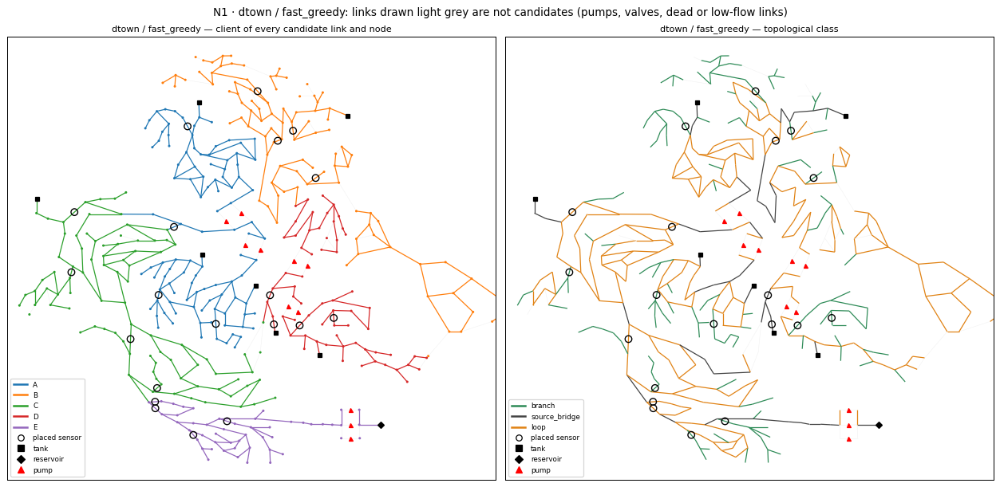

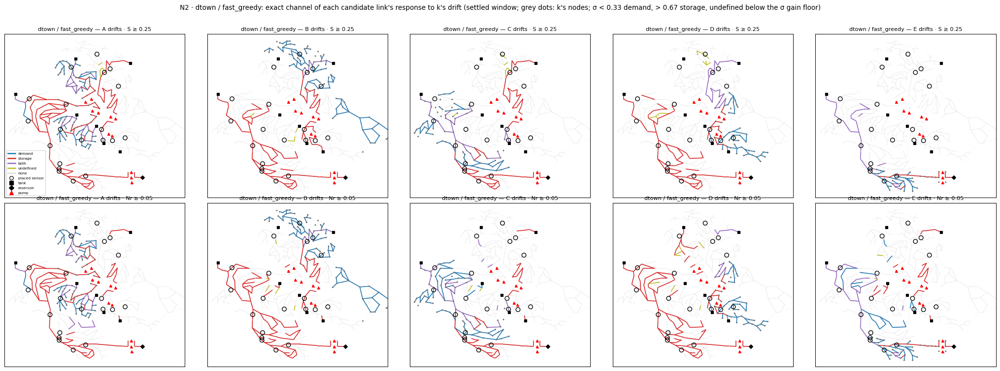

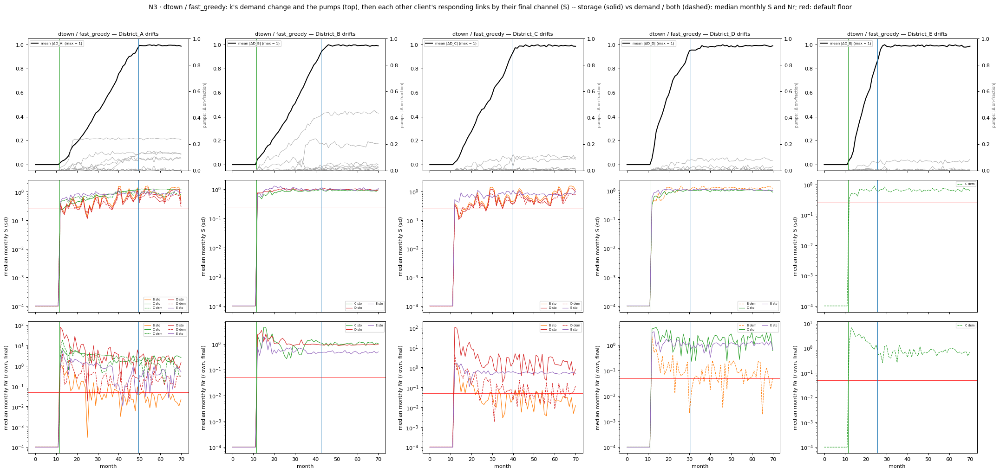

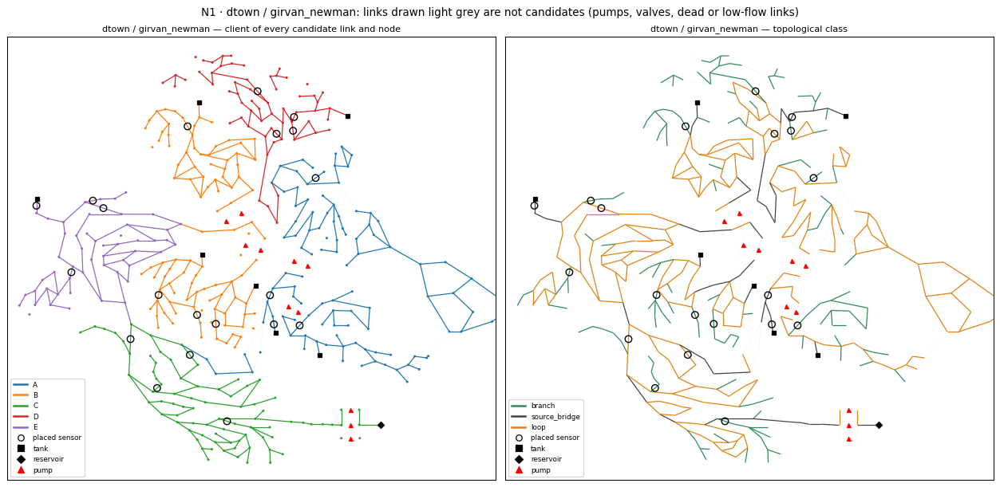

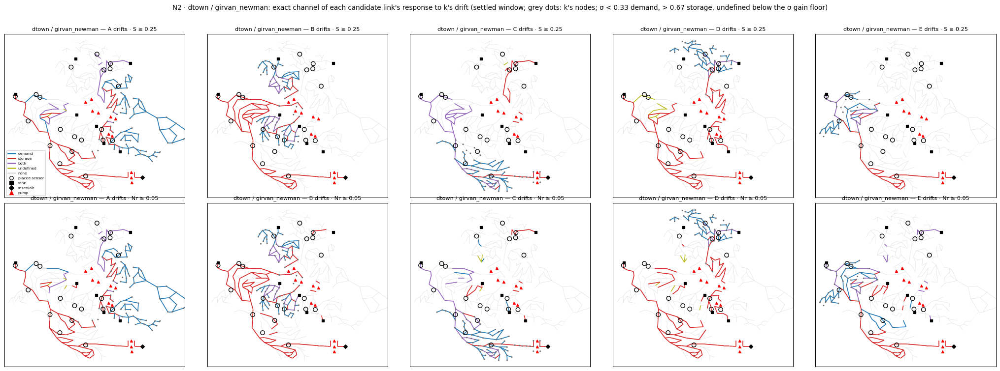

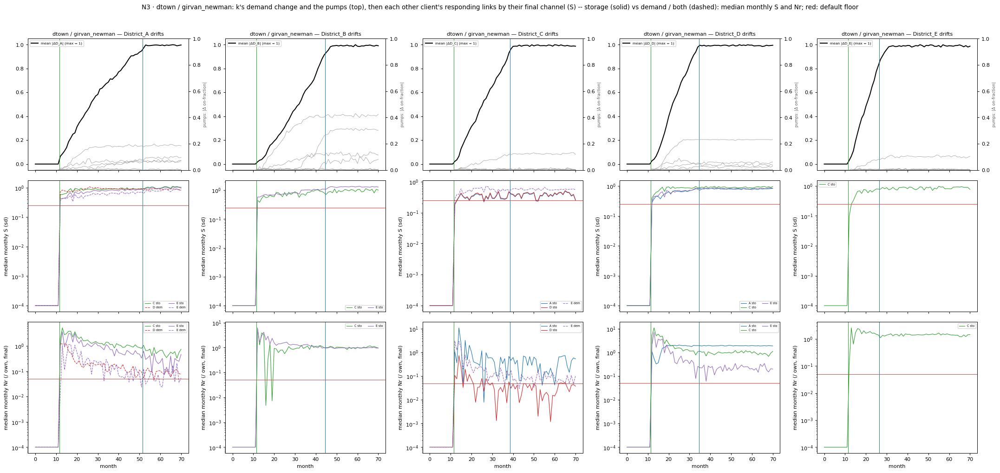

In [13]:
# N. maps: the partition and its classes, the exact channel of every response, and the chain through the months
CH_COL = {"demand": "#1f77b4", "storage": "#d62728", "both": "#9467bd", "undefined": "#bcbd22", "none": "#dddddd"}
TOPO_COL = {"branch": "#2e8b57", "source_bridge": "#444444", "loop": "#e08214", "isolated": "#999999"}
CHN, GEO, NOD, PMO = TB["channel"], TB["geometry"], TB["nodes"], TB.get("pumps_monthly", pd.DataFrame())
MARK = [Line2D([0], [0], marker="o", ls="", mfc="none", mec="k", label="placed sensor"),
        Line2D([0], [0], marker="s", ls="", color="k", label="tank"), Line2D([0], [0], marker="D", ls="", color="k", label="reservoir"),
        Line2D([0], [0], marker="^", ls="", color="r", label="pump")]

for p in PARTS:
    nd = NOD[NOD["part"] == p].assign(node=lambda d: d["node"].astype(str)).drop_duplicates("node").set_index("node")
    gm = GEO[GEO["part"] == p].assign(start=lambda d: d["start"].astype(str), end=lambda d: d["end"].astype(str))
    gm = gm[gm["start"].isin(nd.index) & gm["end"].isin(nd.index)]
    SEG = {r.element: [(nd.at[r.start, "x"], nd.at[r.start, "y"]), (nd.at[r.end, "x"], nd.at[r.end, "y"])]
           for r in gm.itertuples()}
    MID = {e: ((a[0] + b[0]) / 2, (a[1] + b[1]) / 2) for e, (a, b) in SEG.items()}
    jn = nd[nd["kind"] == "junction"]
    (x0, x1), (y0, y1) = jn["x"].quantile([0.005, 0.995]), jn["y"].quantile([0.005, 0.995])

    def base_map(ax, lines_col, lines_w, node_col=None, title=""):
        segs = list(SEG)
        ax.add_collection(LineCollection([SEG[e] for e in segs], colors=[lines_col.get(e, "#f0f0f0") for e in segs],
                                         linewidths=[lines_w.get(e, 0.4) for e in segs]))
        if node_col is not None:
            q_ = nd.loc[nd.index.intersection(node_col.index)]
            ax.scatter(q_["x"], q_["y"], s=2, c=[node_col[n] for n in q_.index], zorder=2)
        pm = [MID[e] for e in PLACED[p] if e in MID]
        if pm:
            ax.scatter(*zip(*pm), s=46, facecolors="none", edgecolors="k", lw=1.1, zorder=4)
        for kind, mk in (("tank", "s"), ("reservoir", "D")):
            q_ = nd[nd["kind"] == kind]
            ax.plot(q_["x"], q_["y"], mk, color="k", ms=4, zorder=5)
        for e in gm[gm["is_pump"].astype(bool)]["element"]:
            if e in MID:
                ax.plot(*MID[e], "^", color="r", ms=4, zorder=5)
        px, py = 0.05 * (x1 - x0), 0.05 * (y1 - y0)
        ax.set_xlim(x0 - px, x1 + px); ax.set_ylim(y0 - py, y1 + py)
        ax.set_aspect("equal"); ax.set_xticks([]); ax.set_yticks([]); ax.set_title(title, fontsize=9)

    lk = gm[gm["candidate"].astype(bool)].set_index("element")
    ks = sorted(PER[PER["part"] == p]["k"])
    ndd = nd["district"].dropna()
    # N1 · the partition and the classes
    fig, axes = plt.subplots(1, 2, figsize=(14, 7))
    base_map(axes[0], {e: DCOL.get(h) for e, h in lk["home"].items()}, {e: 1.0 for e in lk.index},
             ndd.map(DCOL), f"{p} — client of every candidate link and node")
    base_map(axes[1], {e: TOPO_COL.get(t, "#999999") for e, t in lk["topo"].items()}, {e: 1.0 for e in lk.index},
             None, f"{p} — topological class")
    axes[0].legend(handles=[Line2D([0], [0], color=DCOL[d], lw=2, label=short(d)) for d in ks] + MARK, fontsize=7, loc="lower left")
    axes[1].legend(handles=[Line2D([0], [0], color=c, lw=2, label=t) for t, c in TOPO_COL.items() if t in set(lk["topo"])] + MARK,
                   fontsize=7, loc="lower left")
    fig.suptitle(f"N1 · {p}: links drawn light grey are not candidates (pumps, valves, dead or low-flow links)")
    fig.tight_layout(); plt.show()

    # N2 · where the response is, by exact channel (rows: shape S, native Nr)
    fig, axes = plt.subplots(2, len(ks), figsize=(4.6 * len(ks), 8.5), squeeze=False)
    for i, x in enumerate(("S", "Nr")):
        for j, k in enumerate(ks):
            c_ = CHN[(CHN["part"] == p) & (CHN["k"] == k) & (CHN["metric"] == x)].set_index("element")["channel"]
            kn = ndd[ndd == k]
            base_map(axes[i, j], {e: CH_COL[c] for e, c in c_.items()}, {e: (1.3 if c != "none" else 0.5) for e, c in c_.items()},
                     pd.Series("0.45", index=kn.index), f"{p} — {short(k)} drifts · {x} ≥ {FLOOR[x]:g}")
    axes[0, 0].legend(handles=[Line2D([0], [0], color=c, lw=2, label=l) for l, c in CH_COL.items()] + MARK,
                      fontsize=6, loc="lower left")
    fig.suptitle(f"N2 · {p}: exact channel of each candidate link's response to k's drift (settled window; grey dots: k's "
                 f"nodes; σ < {CH_LO:.2f} demand, > {CH_HI:.2f} storage, undefined below the σ gain floor)")
    fig.tight_layout(rect=(0, 0, 1, 0.96)); plt.show()

    # N3 · the chain through the months: k's demand change and the pumps, then each other client's links by channel
    mo = MON[MON["part"] == p]
    fig, axes = plt.subplots(3, len(ks), figsize=(4.8 * len(ks), 11.5), squeeze=False, sharex=True)
    for j, k in enumerate(ks):
        q_ = mo[mo["k"] == k]
        dd = q_.drop_duplicates("month").sort_values("month")
        W = win_of(p, k)
        ax = axes[0, j]
        ax.plot(dd["month"], dd["dD_abs_mean"] / max(dd["dD_abs_mean"].max(), 1e-12), color="k", lw=1.6,
                label=f"mean |ΔD_{short(k)}| (max = 1)")
        pm_ = PMO[(PMO["part"] == p) & (PMO["k"] == k)] if len(PMO) else PMO
        if len(pm_):
            ax2 = ax.twinx()
            for e, g in pm_.groupby("element"):
                g = g.sort_values("month")
                ax2.plot(g["month"], (g["on_drift"] - g["on_nodrift"]).abs(), color="0.6", lw=0.6)
            ax2.set_ylim(0, 1); ax2.set_ylabel("pumps: |Δ on-fraction|", fontsize=7, color="0.4")
        ax.set_title(f"{p} — {k} drifts", fontsize=9); ax.legend(fontsize=6, loc="upper left")
        for i, (x, col, fl) in enumerate((("S", "S", FLOOR["S"]), ("Nr", "Nr_final", FLOOR["Nr"])), start=1):
            ax = axes[i, j]
            for jj in [d for d in ks if d != k]:
                for chs, ls, lab_ in ((("storage",), "-", "sto"), (("demand", "both"), "--", "dem")):
                    g = q_[(q_["home"] == jj) & q_["channel_S"].isin(chs)].groupby("month")[col].median()
                    if len(g):
                        ax.plot(g.index, g.clip(lower=1e-4), ls=ls, color=DCOL[jj], lw=0.9, label=f"{short(jj)} {lab_}")
            ax.axhline(fl, color="r", lw=0.6)
            for a_ in axes[:, j]:
                for edge, c in ((W["transition"][0] / W["sm"], "#2ca02c"), (W["final"][0] / W["sm"], "#1f77b4")):
                    a_.axvline(edge - 0.5, color=c, lw=0.8)
            ax.set_yscale("log"); ax.set_ylabel(f"median monthly {x}" + (" (sd)" if x == "S" else " (/ own, final)"))
            ax.legend(fontsize=5, ncol=2)
        axes[-1, j].set_xlabel("month")
    fig.suptitle(f"N3 · {p}: k's demand change and the pumps (top), then each other client's responding links by their final "
                 f"channel (S) -- storage (solid) vs demand / both (dashed): median monthly S and Nr; red: default floor")
    fig.tight_layout(rect=(0, 0, 1, 0.96)); plt.show()